# RL-дообучение GPT-2 рекомендера на KION

Последовательная рекомендательная модель (GPT-2, токены – идентификаторы фильмов и сериалов) дообучается с помощью RL так, чтобы рекомендации имели более высокую предсказанную долю просмотра. Исследуется, что при этом происходит с релевантностью и поведением модели.

Ноутбук выполнен на Kaggle (T4, полный прогон, 137 минут). Краткий отчёт – в README репозитория.

**Содержание**

1. Данные и разбиение по времени
2. Базовая модель: GPT-2, next item prediction, бейзлайны
3. Reward model по `watched_pct`
4. RL-дообучение: GRPO + KL, дополнительные reward model, сетка прогонов
5. Анализ: reward против релевантности, поведение, группы пользователей, экспозиция, фактические исходы, релевантность по 6 событиям, знакомый контент, подтверждение reward, разброс по seed
6. Генерация на 5 шагов вперёд
7. Компромисс, финальная оценка на test, reward model на test
8. Выводы и ограничения

In [1]:
import os, glob, json, random
from pathlib import Path
import numpy as np

ON_KAGGLE = os.path.exists("/kaggle/input")
SMOKE = not ON_KAGGLE   # локально: малая выборка; на Kaggle: полный прогон (для быстрой проверки на Kaggle поставьте True)
SEED = 42

WORK = Path("/kaggle/working") if ON_KAGGLE else Path(".")
CACHE, CKPT, RESULTS = WORK/"cache", WORK/"checkpoints", WORK/"results"
for d in (CACHE, CKPT, RESULTS): d.mkdir(exist_ok=True)

def find_data_dir():
    if os.environ.get("DATA_DIR"): return Path(os.environ["DATA_DIR"])
    hits = glob.glob("/kaggle/input/**/interactions.csv", recursive=True)
    if not hits: raise FileNotFoundError("interactions.csv не найден: подключите датасет или задайте DATA_DIR")
    return Path(hits[0]).parent
DATA_DIR = find_data_dir()

random.seed(SEED); np.random.seed(SEED)
print("kaggle:", ON_KAGGLE, "| smoke:", SMOKE, "| data:", DATA_DIR)

kaggle: True | smoke: False | data: /kaggle/input/kion-mts


## 1. Данные и разбиение по времени

**Протокол разбиения** (один для всех моделей):

- Глобальные даты: train `< 2021-08-02`, val `2021-08-02 … 08-08`, test `2021-08-09 … 08-22` (последние 14 дней).
- Обучение (GPT-2, reward model, RL) использует только train. Val нужна для подбора настроек, test открываем один раз в конце.
- Eval-кейс: пользователь с ≥5 событиями в train и ≥1 событием в периоде. Цель – первое событие в периоде, контекст – все события пользователя до начала периода (для test это train+val). Следующие 5 событий периода сохраняем как «будущее» для проверки 5-шаговой генерации.
- Объекты, которых нет в train, из val/test выкидываем (холодный старт здесь не исследуем), долю считаем и печатаем.
- В KION есть только дата без времени: порядок внутри дня берём из порядка строк файла (стабильная сортировка). Это шум, он описан в ограничениях.
- Пара (пользователь, объект) в данных не повторяется, поэтому уже просмотренные объекты исключаем из рекомендаций при оценке.

In [2]:
import pandas as pd

TRAIN_END = pd.Timestamp("2021-08-02")   # train: dt < TRAIN_END
VAL_END   = pd.Timestamp("2021-08-09")   # val: [TRAIN_END, VAL_END), test: >= VAL_END
MIN_HIST  = 5                            # минимум событий в train
N_FUTURE  = 5                            # длина «будущего» для многошагового анализа
SMOKE_USERS = 30_000                     # размер выборки пользователей при SMOKE=True
TAG = "smoke" if SMOKE else "full"

In [3]:
def build_split():
    df = pd.read_csv(DATA_DIR/"interactions.csv", parse_dates=["last_watch_dt"])
    n_raw = len(df)
    df = df.dropna(subset=["watched_pct"]).reset_index(drop=True)
    df["row"] = np.arange(len(df))
    df = df.sort_values(["user_id", "last_watch_dt", "row"], kind="mergesort").reset_index(drop=True)
    df["period"] = np.select([df.last_watch_dt < TRAIN_END, df.last_watch_dt < VAL_END], [0, 1], 2)  # 0 train, 1 val, 2 test

    n_train = df[df.period == 0].groupby("user_id").size()
    keep = n_train[n_train >= MIN_HIST].index
    if SMOKE:
        keep = pd.Index(np.random.RandomState(SEED).choice(keep, SMOKE_USERS, replace=False))
    df = df[df.user_id.isin(keep)].copy()

    # словарь объектов только по train; 0 зарезервирован под PAD
    train_items = np.sort(df.loc[df.period == 0, "item_id"].unique())
    item2idx = {it: i + 1 for i, it in enumerate(train_items)}
    seen = df.item_id.isin(item2idx)
    unseen_share = {p: float((~seen[df.period == p]).mean()) for p in (1, 2)}
    df = df[seen].copy()
    df["item"] = df.item_id.map(item2idx).astype("int32")
    df = df[["user_id", "item", "item_id", "last_watch_dt", "watched_pct", "total_dur", "period"]].reset_index(drop=True)
    return df, item2idx, unseen_share, n_raw

cache_f = CACHE/f"interactions_{TAG}.parquet"
if cache_f.exists():
    df = pd.read_parquet(cache_f)
    item2idx = {it: i + 1 for i, it in enumerate(np.sort(df.loc[df.period == 0, "item_id"].unique()))}
    unseen_share = json.load(open(RESULTS/f"split_stats_{TAG}.json"))["unseen_share"]
else:
    df, item2idx, unseen_share, n_raw = build_split()
    df.to_parquet(cache_f)
n_items = len(item2idx) + 1   # с учётом PAD=0
print(df.shape, "users:", df.user_id.nunique(), "| vocab:", n_items)

(3726252, 7) users: 240240 | vocab: 14902


Eval-кейсы: цель, контекст (индексы строк в `df`) и «будущее» из 5 событий.

In [4]:
def build_eval(df, period):
    """Одна строка на пользователя: первое событие периода — цель, следующие N_FUTURE — будущее."""
    cur = df[df.period == period]
    g = cur.groupby("user_id", sort=False)
    first = g.head(1).set_index("user_id")
    fut = g.head(1 + N_FUTURE).groupby("user_id", sort=False).item.apply(lambda s: s.iloc[1:].tolist())
    out = pd.DataFrame({"target": first["item"], "target_pct": first["watched_pct"],
                        "target_dt": first["last_watch_dt"], "future": fut})
    return out

evals = {"val": build_eval(df, 1), "test": build_eval(df, 2)}

def history(user_id, period):
    """Контекст пользователя: все события строго до начала периода."""
    u = df_by_user.get_group(user_id)
    return u[u.period < period]

df_by_user = df.groupby("user_id", sort=False)
for k, e in evals.items(): print(k, "eval users:", len(e))

val eval users: 58173
test eval users: 74148


Проверки на утечки и статистика.

In [5]:
tr, va, te = (df[df.period == p] for p in (0, 1, 2))
assert tr.last_watch_dt.max() < TRAIN_END
assert va.last_watch_dt.between(TRAIN_END, VAL_END - pd.Timedelta(days=1)).all()
assert te.last_watch_dt.min() >= VAL_END
assert df.groupby("user_id").last_watch_dt.apply(lambda s: s.is_monotonic_increasing).all()   # сортировка по времени
assert set(va.item) <= set(tr.item) and set(te.item) <= set(tr.item)                             # словарь только из train
assert not df.duplicated(["user_id", "item"]).any()                                              # нет повторов, значит цель не из истории
for k, p in (("val", 1), ("test", 2)):                                                           # цель всегда позже истории
    e = evals[k]; hist_last = df[df.period < p].groupby("user_id").last_watch_dt.max()
    assert (e.target_dt.values >= hist_last.reindex(e.index).values).all()

stats = {
    "tag": TAG, "users": int(df.user_id.nunique()), "vocab": int(n_items),
    "events": {"train": len(tr), "val": len(va), "test": len(te)},
    "train_seq_len_median": float(tr.groupby("user_id").size().median()),
    "eval_users": {k: len(e) for k, e in evals.items()},
    "unseen_share": unseen_share,
    "watched_pct_mean": {"train": float(tr.watched_pct.mean()), "val": float(va.watched_pct.mean()), "test": float(te.watched_pct.mean())},
    "share_pct_ge_50": {"train": float((tr.watched_pct >= 50).mean()), "test": float((te.watched_pct >= 50).mean())},
}
json.dump(stats, open(RESULTS/f"split_stats_{TAG}.json", "w"), indent=1)
print(json.dumps(stats, indent=1)); print("утечек не найдено")

{
 "tag": "full",
 "users": 240240,
 "vocab": 14902,
 "events": {
  "train": 3265457,
  "val": 177981,
  "test": 282814
 },
 "train_seq_len_median": 9.0,
 "eval_users": {
  "val": 58173,
  "test": 74148
 },
 "unseen_share": {
  "1": 0.029536854273219993,
  "2": 0.08647972944600386
 },
 "watched_pct_mean": {
  "train": 51.091070254485054,
  "val": 44.3972446497098,
  "test": 44.67111953439363
 },
 "share_pct_ge_50": {
  "train": 0.49039690309809625,
  "test": 0.4161250857454016
 }
}
утечек не найдено


## 2. Базовая модель (GPT-2, next item prediction)

**Модель и протокол оценки.**

- GPT-2 (HF `GPT2LMHeadModel`, веса с нуля), токен = индекс объекта, 0 = PAD. Контекст – последние 50 объектов.
- Обучение: train-период, окна по 50 объектов со сдвигом 25, loss = кросс-энтропия next item.
- Оценка: ранжируем весь каталог, **исключая уже просмотренные объекты и PAD**. Единственный релевантный объект – цель кейса, поэтому Recall@K = HitRate@K, а MAP@K = MRR@K.
- Все модели (бейзлайны, база, позже RL) оцениваются одной функцией `evaluate`. Ничья по score считается как худший ранг.
- Доверительные интервалы 95%: бутстреп по пользователям (1000 повторов); для разности моделей – парный бутстреп.
- Разнообразие: покрытие каталога в топ-10, Gini экспозиции объектов, средняя лог-популярность рекомендаций.

In [6]:
import torch, time
from transformers import GPT2Config, GPT2LMHeadModel

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MAX_LEN, KS, K_MAX = 50, (5, 10, 20), 20
CFG = (dict(n_layer=2, n_head=4, n_embd=128, epochs=3, bs=64, lr=1e-3) if SMOKE
       else dict(n_layer=4, n_head=4, n_embd=256, epochs=6, bs=256, lr=5e-4))
torch.manual_seed(SEED)
print(DEVICE, CFG)

item_cnt = np.bincount(df.loc[df.period == 0, "item"].values, minlength=n_items)   # популярность в train

def pad(seqs, dtype=np.int64):
    a = np.zeros((len(seqs), max(map(len, seqs))), dtype)
    for i, s in enumerate(seqs): a[i, :len(s)] = s
    return torch.from_numpy(a)

_hist_cache = {}
def histories(split):
    """Полная история каждого eval-пользователя: все события строго до начала периода."""
    if split in _hist_cache: return _hist_cache[split]
    p = {"val": 1, "test": 2}[split]
    sub = df[df.period < p]; uid, it = sub.user_id.values, sub.item.values
    starts = np.flatnonzero(np.r_[True, uid[1:] != uid[:-1]]); ends = np.r_[starts[1:], len(uid)]
    pos = pd.Series(np.arange(len(starts)), index=uid[starts]).reindex(evals[split].index).values
    _hist_cache[split] = [it[starts[j]:ends[j]] for j in pos]
    return _hist_cache[split]

@torch.no_grad()
def evaluate(score_fn, split, bs=512, limit=None):
    """score_fn(ctx[B,L], lens[B]) -> scores[B,V]. Возвращает ранг цели и топ-K_MAX рекомендаций."""
    e, hist = evals[split].iloc[:limit], histories(split)[:limit]
    tgt = e.target.values.astype(np.int64)
    ranks, recs = np.empty(len(e), np.int64), np.empty((len(e), K_MAX), np.int64)
    for i in range(0, len(e), bs):
        hb = hist[i:i + bs]
        ctx = pad([h[-MAX_LEN:] for h in hb]); lens = torch.tensor([min(len(h), MAX_LEN) for h in hb])
        sc = score_fn(ctx.to(DEVICE), lens.to(DEVICE)).clone()
        sc[:, 0] = -float("inf")
        rows = torch.from_numpy(np.concatenate([np.full(len(h), j) for j, h in enumerate(hb)]))
        cols = torch.from_numpy(np.concatenate(hb).astype(np.int64))
        sc[rows.to(DEVICE), cols.to(DEVICE)] = -float("inf")           # просмотренное не рекомендуем
        t = torch.from_numpy(tgt[i:i + bs]).to(DEVICE)
        ranks[i:i + bs] = (sc >= sc.gather(1, t[:, None])).sum(1).cpu().numpy()
        recs[i:i + bs] = sc.topk(K_MAX, 1).indices.cpu().numpy()
    return ranks, recs

def user_metrics(ranks):
    m = {}
    for k in KS:
        hit = ranks <= k
        m[f"Recall@{k}"], m[f"NDCG@{k}"], m[f"MAP@{k}"] = hit * 1.0, hit / np.log2(ranks + 1), hit / ranks
    return m

def boot_ci(x, B=1000, seed=0):
    """Среднее и 95% ДИ бутстрепом по пользователям."""
    rng, n, means = np.random.default_rng(seed), len(x), np.empty(B)
    for s in range(0, B, 100):
        means[s:s + 100] = x[rng.integers(0, n, (min(100, B - s), n))].mean(1)
    return [float(x.mean()), *map(float, np.percentile(means, [2.5, 97.5]))]

def diversity(recs, k=10):
    r = recs[:, :k].ravel(); cnt = np.bincount(r, minlength=n_items)[1:]
    p = np.sort(cnt) / cnt.sum(); n = len(p)
    return {"coverage@10": float((cnt > 0).mean()), "gini@10": float((2 * np.arange(1, n + 1) - n - 1) @ p / n),
            "mean_log_pop@10": float(np.log1p(item_cnt[r]).mean())}

def diversity_ci(recs, B=200, seed=0):
    rng, base = np.random.default_rng(seed), diversity(recs)
    boots = [diversity(recs[rng.integers(0, len(recs), len(recs))]) for _ in range(B)]
    q = {k: np.percentile([b[k] for b in boots], [2.5, 97.5]) for k in base}
    out = {k: [v, *map(float, q[k])] for k, v in base.items()}
    out["coverage@10"] = [base["coverage@10"], None, None]   # при пересэмплировании пользователей покрытие смещается вниз: ДИ не считаем
    return out

def report(ranks, recs):
    return {**{k: boot_ci(v) for k, v in user_metrics(ranks).items()}, **diversity_ci(recs)}

def table(res, cols=("Recall@10", "NDCG@10", "MAP@10", "Recall@20", "coverage@10", "gini@10", "mean_log_pop@10")):
    fmt = lambda x: f"{x[0]:.4f}" if x[1] is None else f"{x[0]:.4f} [{x[1]:.4f}, {x[2]:.4f}]"
    return pd.DataFrame({m: {c: fmt(r[c]) for c in cols} for m, r in res.items()}).T

cuda {'n_layer': 4, 'n_head': 4, 'n_embd': 256, 'epochs': 6, 'bs': 256, 'lr': 0.0005}


### Бейзлайны: популярное за всё время и за последние 7 дней train

In [7]:
last7 = df[(df.period == 0) & (df.last_watch_dt >= TRAIN_END - pd.Timedelta(days=7))]
cnt7 = np.bincount(last7.item.values, minlength=n_items)
pop_all = torch.tensor(item_cnt, dtype=torch.float32, device=DEVICE)
pop_7d = torch.tensor(cnt7 + 1e-6 * item_cnt, dtype=torch.float32, device=DEVICE)   # хвост разруливаем общей популярностью

val_res, val_raw = {}, {}
for name, vec in (("Pop (all time)", pop_all), ("Pop (last 7d)", pop_7d)):
    r, rec = evaluate(lambda c, l, v=vec: v[None].expand(len(c), -1), "val")
    val_raw[name] = (r, rec); val_res[name] = report(r, rec)
table(val_res)

,Recall@10,NDCG@10,MAP@10,Recall@20,coverage@10,gini@10,mean_log_pop@10
Pop (all time),"0.1398 [0.1372, 0.1427]","0.0833 [0.0815, 0.0851]","0.0656 [0.0640, 0.0674]","0.1857 [0.1827, 0.1889]",0.0025,"0.9991 [0.9991, 0.9991]","10.4683 [10.4666, 10.4701]"
Pop (last 7d),"0.1956 [0.1924, 0.1990]","0.1023 [0.1005, 0.1041]","0.0742 [0.0726, 0.0758]","0.2570 [0.2535, 0.2607]",0.0021,"0.9992 [0.9992, 0.9992]","9.5501 [9.5479, 9.5522]"


### Обучение GPT-2

In [8]:
def make_windows(stride=MAX_LEN // 2):
    tr = df[df.period == 0]; uid, it = tr.user_id.values, tr.item.values
    starts = np.flatnonzero(np.r_[True, uid[1:] != uid[:-1]]); ends = np.r_[starts[1:], len(uid)]
    out = []
    for s, e in zip(starts, ends):
        seq = it[s:e]
        if len(seq) <= MAX_LEN: out.append(seq); continue
        out += [seq[end - MAX_LEN:end] for end in range(len(seq), MAX_LEN - 1, -stride)]
        if (len(seq) - MAX_LEN) % stride: out.append(seq[:MAX_LEN])
    return out

def new_model():
    cfg = GPT2Config(vocab_size=n_items, n_positions=MAX_LEN, n_embd=CFG["n_embd"], n_layer=CFG["n_layer"],
                     n_head=CFG["n_head"], pad_token_id=0, bos_token_id=0, eos_token_id=0)
    return GPT2LMHeadModel(cfg).to(DEVICE)

def gpt_scores(model):
    def f(ctx, lens):
        h = model.transformer(input_ids=ctx, attention_mask=(ctx != 0).long()).last_hidden_state
        return model.lm_head(h[torch.arange(len(ctx), device=ctx.device), lens - 1]).float()
    return f

def train_base(model, seqs, log_path):
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=0.01)
    steps = CFG["epochs"] * ((len(seqs) + CFG["bs"] - 1) // CFG["bs"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, CFG["lr"], total_steps=steps, pct_start=0.1)
    amp = DEVICE == "cuda"; scaler = torch.amp.GradScaler(enabled=amp)
    log, best = [], -1
    for ep in range(CFG["epochs"]):
        model.train(); t0, losses = time.time(), []
        perm = np.random.permutation(len(seqs))
        for i in range(0, len(seqs), CFG["bs"]):
            x = pad([seqs[j] for j in perm[i:i + CFG["bs"]]]).to(DEVICE)
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=amp):
                loss = model(input_ids=x, attention_mask=(x != 0).long(), labels=x.masked_fill(x == 0, -100)).loss
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); losses.append(loss.item())
        model.eval(); r, _ = evaluate(gpt_scores(model), "val"); rec10 = float((r <= 10).mean())
        log.append(dict(epoch=ep + 1, train_loss=float(np.mean(losses)), val_recall10=rec10, sec=round(time.time() - t0)))
        print(log[-1])
        if rec10 > best: best = rec10; torch.save(model.state_dict(), CKPT/f"base_{TAG}.pt")
    pd.DataFrame(log).to_csv(log_path, index=False)

seqs = make_windows(); print("train windows:", len(seqs))
base = new_model(); print("params:", sum(p.numel() for p in base.parameters()))
if (CKPT/f"base_{TAG}.pt").exists():
    print("загружаю чекпойнт")
else:
    train_base(base, seqs, RESULTS/f"base_train_log_{TAG}.csv")
base.load_state_dict(torch.load(CKPT/f"base_{TAG}.pt", map_location=DEVICE)); _ = base.eval()

train windows: 251467
params: 6987264


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


{'epoch': 1, 'train_loss': 7.216848008630235, 'val_recall10': 0.18852388565141903, 'sec': 132}
{'epoch': 2, 'train_loss': 6.506850705384481, 'val_recall10': 0.2079658948309353, 'sec': 133}
{'epoch': 3, 'train_loss': 6.381937306385681, 'val_recall10': 0.20775961356643116, 'sec': 132}
{'epoch': 4, 'train_loss': 6.305342793100848, 'val_recall10': 0.21138672580062917, 'sec': 132}
{'epoch': 5, 'train_loss': 6.249445885146986, 'val_recall10': 0.21150705653825658, 'sec': 133}
{'epoch': 6, 'train_loss': 6.218366263962956, 'val_recall10': 0.21231499149089783, 'sec': 132}


### Базовая модель на val против бейзлайнов

In [9]:
r, rec = evaluate(gpt_scores(base), "val")
val_raw["GPT-2 base"] = (r, rec); val_res["GPT-2 base"] = report(r, rec)
json.dump(val_res, open(RESULTS/f"base_val_{TAG}.json", "w"), indent=1)
display(table(val_res))

# парная разность с лучшим бейзлайном
best_bl = max(("Pop (all time)", "Pop (last 7d)"), key=lambda n: val_res[n]["NDCG@10"][0])
for m in ("Recall@10", "NDCG@10"):
    d = user_metrics(val_raw["GPT-2 base"][0])[m] - user_metrics(val_raw[best_bl][0])[m]
    c = boot_ci(d)
    print(f"{m}: GPT-2 base - {best_bl} = {c[0]:.4f}, 95% ДИ [{c[1]:.4f}, {c[2]:.4f}]")

,Recall@10,NDCG@10,MAP@10,Recall@20,coverage@10,gini@10,mean_log_pop@10
Pop (all time),"0.1398 [0.1372, 0.1427]","0.0833 [0.0815, 0.0851]","0.0656 [0.0640, 0.0674]","0.1857 [0.1827, 0.1889]",0.0025,"0.9991 [0.9991, 0.9991]","10.4683 [10.4666, 10.4701]"
Pop (last 7d),"0.1956 [0.1924, 0.1990]","0.1023 [0.1005, 0.1041]","0.0742 [0.0726, 0.0758]","0.2570 [0.2535, 0.2607]",0.0021,"0.9992 [0.9992, 0.9992]","9.5501 [9.5479, 9.5522]"
GPT-2 base,"0.2123 [0.2090, 0.2155]","0.1258 [0.1237, 0.1281]","0.0993 [0.0973, 0.1014]","0.2829 [0.2793, 0.2866]",0.2431,"0.9814 [0.9814, 0.9818]","8.9994 [8.9925, 9.0067]"


Recall@10: GPT-2 base - Pop (last 7d) = 0.0168, 95% ДИ [0.0139, 0.0199]
NDCG@10: GPT-2 base - Pop (last 7d) = 0.0235, 95% ДИ [0.0217, 0.0254]


### Выводы по базовой модели

- GPT-2 (7.0 млн параметров, 6 эпох, около 13 минут на T4) на val: Recall@10 0.212 [0.209, 0.216], NDCG@10 0.126 [0.124, 0.128], MAP@10 0.099. Лучший бейзлайн, популярное за последние 7 дней, даёт 0.196 и 0.102. Разность по Recall@10 +0.017 [+0.014, +0.020], по NDCG@10 +0.024 [+0.022, +0.025].
- Популярное за 7 дней заметно сильнее популярного за всё время (Recall@10 0.196 против 0.140): тренд KION быстро меняется. При разбиении без учёта времени оценки были бы завышены.
- Покрытие каталога в топ-10: 0.243 у GPT-2 и 0.002 у популярного. При этом 73% всех слотов рекомендаций приходится на 100 объектов: экспозиция сосредоточена на популярном и у базовой модели.
- На test Recall@10 ниже (0.196), чем на val (0.212): дрейф по времени, средний `watched_pct` в test 44.7 против 51.1 в train.

## 3. Reward model (watched_pct)

**Постановка.** Reward model (RM) предсказывает `watched_pct / 100` для пары (история пользователя, объект-кандидат).

- Архитектура: каузальный GPT-2-энкодер над историей даёт вектор `h_t`; предсказание для события `t+1` = `sigmoid(MLP([h_t, emb(item_{t+1})]))`. За один проход по окну из 50 событий получаем предсказания для всех позиций.
- Вход истории: эмбеддинг объекта + эмбеддинг его `watched_pct` (уровень вовлечённости пользователя – самый сильный сигнал). Во время обучения у 50% окон отклики заменяются на обучаемый вектор «неизвестно», чтобы RM работала и на сгенерированных последовательностях, где откликов нет.
- Обучение: train-период, MSE. Оценка на val: все события val (контекст – всё, что было раньше у пользователя, включая более ранние события val; берём последние 50 событий).
- Сравнение с бейзлайнами без контекста: константа, среднее по объекту, среднее по пользователю, их сумма (все со сглаживанием по 5 событиям, считаются по train).
- Метрики: MAE, RMSE, AUC для «досмотрел» (`watched_pct ≥ 50`), Spearman; ДИ бутстрепом по пользователям (200 повторов); калибровка по децилям.
- RM обучена только на реальных историях. На сгенерированных последовательностях (секция 6) она работает вне распределения, это учтём в выводах.

In [10]:
from torch import nn
from transformers import GPT2Model
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

RM_CFG = (dict(n_layer=2, n_head=4, n_embd=128, epochs=2, bs=32, lr=1e-3) if SMOKE
          else dict(n_layer=2, n_head=4, n_embd=256, epochs=3, bs=256, lr=5e-4))

class RewardModel(nn.Module):
    def __init__(self, n_items, d, n_layer, n_head):
        super().__init__()
        self.backbone = GPT2Model(GPT2Config(vocab_size=n_items, n_positions=MAX_LEN, n_embd=d, n_layer=n_layer, n_head=n_head))
        self.cand = nn.Embedding(n_items, d, padding_idx=0)      # отдельные эмбеддинги кандидата
        self.head = nn.Sequential(nn.Linear(2 * d, d), nn.GELU(), nn.Dropout(0.1), nn.Linear(d, 1))
        self.pct_proj = nn.Sequential(nn.Linear(1, d), nn.GELU(), nn.Linear(d, d))   # отклик на прошлое событие
        self.unk = nn.Parameter(torch.zeros(d))                                      # «отклик неизвестен»
    def hidden(self, ctx, pct=None):
        """pct[B,L] в [0,1] или -1 (неизвестно); pct=None: все отклики неизвестны."""
        e = self.backbone.wte(ctx)
        if pct is None: pct = torch.full(ctx.shape, -1.0, device=ctx.device)
        pe = torch.where((pct >= 0)[..., None], self.pct_proj(pct.clamp(min=0)[..., None].to(e.dtype)), self.unk.to(e.dtype))
        return self.backbone(inputs_embeds=e + pe, attention_mask=(ctx != 0).long()).last_hidden_state
    def score(self, h, cand):                                    # h[...,d], cand[...] -> доля просмотра в (0,1)
        return torch.sigmoid(self.head(torch.cat([h, self.cand(cand)], -1)).squeeze(-1))

@torch.no_grad()
def rm_candidates(rm, ctx, lens, cand, ctx_pct=None):
    """Предсказанная доля просмотра для кандидатов cand[B,K] при контексте ctx[B,L] (понадобится в RL)."""
    h = rm.hidden(ctx, ctx_pct)[torch.arange(len(ctx), device=ctx.device), lens - 1]
    return rm.score(h[:, None, :].expand(-1, cand.shape[1], -1), cand)

def window_ranges(n, stride=MAX_LEN // 2):
    if n <= MAX_LEN: return [(0, n)]
    r = [(e - MAX_LEN, e) for e in range(n, MAX_LEN - 1, -stride)]
    return r + ([(0, MAX_LEN)] if (n - MAX_LEN) % stride else [])

def rm_train_windows():
    tr = df[df.period == 0]; uid, it, y = tr.user_id.values, tr.item.values, tr.watched_pct.values / 100
    starts = np.flatnonzero(np.r_[True, uid[1:] != uid[:-1]]); ends = np.r_[starts[1:], len(uid)]
    return [(it[s + a:s + b], y[s + a:s + b].astype(np.float32)) for s, e in zip(starts, ends) for a, b in window_ranges(e - s)]

_rmw_cache = {}
def rm_windows(split):
    """Последние 50 событий каждого eval-пользователя до конца периода; flag — событие принадлежит периоду."""
    if split in _rmw_cache: return _rmw_cache[split]
    p = {"val": 1, "test": 2}[split]
    sub = df[df.period <= p]; uid, it, y, per = sub.user_id.values, sub.item.values, sub.watched_pct.values / 100, sub.period.values
    starts = np.flatnonzero(np.r_[True, uid[1:] != uid[:-1]]); ends = np.r_[starts[1:], len(uid)]
    pos = pd.Series(np.arange(len(starts)), index=uid[starts]).reindex(evals[split].index).values
    sl = [(max(starts[j], ends[j] - MAX_LEN), ends[j]) for j in pos]
    _rmw_cache[split] = ([it[a:b] for a, b in sl], [y[a:b].astype(np.float32) for a, b in sl], [per[a:b] == p for a, b in sl])
    return _rmw_cache[split]

@torch.no_grad()
def rm_predict(rm, split, use_pct=True, bs=512):
    """Предсказания (в процентах) для всех событий периода, у которых есть хотя бы одно событие контекста.
    use_pct: подавать ли реальные отклики контекста (False: «неизвестно»)."""
    items, ys, flags = rm_windows(split); rm.eval()
    P, Y, U, I = [], [], [], []
    for i in range(0, len(items), bs):
        X = pad(items[i:i + bs]).to(DEVICE); Yb = pad(ys[i:i + bs], np.float32); Fb = pad(flags[i:i + bs])[:, 1:].bool()
        pred = rm.score(rm.hidden(X, Yb.to(DEVICE) if use_pct else None)[:, :-1], X[:, 1:]).float().cpu()
        m = Fb & (X[:, 1:].cpu() != 0)
        u = torch.arange(i, i + len(X))[:, None].expand_as(m)
        P.append(pred[m]); Y.append(Yb[:, 1:][m]); U.append(u[m]); I.append(X[:, 1:].cpu()[m])
    cat = lambda l: torch.cat(l).numpy()
    return cat(P) * 100, cat(Y) * 100, cat(U), cat(I)

def train_rm(rm, wins, log_path):
    c = RM_CFG
    opt = torch.optim.AdamW(rm.parameters(), lr=c["lr"], weight_decay=0.01)
    steps = c["epochs"] * ((len(wins) + c["bs"] - 1) // c["bs"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, c["lr"], total_steps=steps, pct_start=0.1)
    amp = DEVICE == "cuda"; scaler = torch.amp.GradScaler(enabled=amp)
    log, best = [], 1e9
    for ep in range(c["epochs"]):
        rm.train(); t0, losses = time.time(), []
        perm = np.random.permutation(len(wins))
        for i in range(0, len(wins), c["bs"]):
            b = [wins[j] for j in perm[i:i + c["bs"]]]
            X = pad([w[0] for w in b]).to(DEVICE); Y = pad([w[1] for w in b], np.float32).to(DEVICE)
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=amp):
                known = torch.rand(len(X), 1, device=DEVICE) < 0.5          # у половины окон отклики скрыты
                pred = rm.score(rm.hidden(X, torch.where(known, Y, torch.full_like(Y, -1.0)))[:, :-1], X[:, 1:])
            v = X[:, 1:] != 0
            loss = ((pred.float() - Y[:, 1:]) ** 2)[v].mean()
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(rm.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); losses.append(loss.item())
        p, y, _, _ = rm_predict(rm, "val"); rmse = float(np.sqrt(((p - y) ** 2).mean()))
        log.append(dict(epoch=ep + 1, train_mse=float(np.mean(losses)) * 1e4, val_rmse=rmse, sec=round(time.time() - t0)))
        print(log[-1])
        if rmse < best: best = rmse; torch.save(rm.state_dict(), CKPT/f"rm_{TAG}.pt")
    pd.DataFrame(log).to_csv(log_path, index=False)

rm = RewardModel(n_items, RM_CFG["n_embd"], RM_CFG["n_layer"], RM_CFG["n_head"]).to(DEVICE)
print("RM params:", sum(p.numel() for p in rm.parameters()))
if not (CKPT/f"rm_{TAG}.pt").exists():
    train_rm(rm, rm_train_windows(), RESULTS/f"rm_train_log_{TAG}.csv")
rm.load_state_dict(torch.load(CKPT/f"rm_{TAG}.pt", map_location=DEVICE)); _ = rm.eval()

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 14901), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 14901), got 50256. This may result in unexpected behavior.


RM params: 9420801
{'epoch': 1, 'train_mse': 1523.983017110388, 'val_rmse': 35.73488998413086, 'sec': 52}
{'epoch': 2, 'train_mse': 1428.5888697948244, 'val_rmse': 35.32790756225586, 'sec': 51}
{'epoch': 3, 'train_mse': 1405.0439529173977, 'val_rmse': 35.18871307373047, 'sec': 51}


### Оценка reward model на val

In [11]:
p_rm, y, uidx, it_val = rm_predict(rm, "val")
n_users_val = len(evals["val"])
tr = df[df.period == 0]; K_SH = 5; g_mean = tr.watched_pct.mean()
im_sum = np.bincount(tr.item.values, weights=tr.watched_pct.values, minlength=n_items)
item_mean = (im_sum + K_SH * g_mean) / (item_cnt + K_SH)                           # среднее по объекту, сглаженное
u_g = tr.groupby("user_id").watched_pct.agg(["sum", "count"])
user_mean = ((u_g["sum"] + K_SH * g_mean) / (u_g["count"] + K_SH)).reindex(evals["val"].index[uidx]).values
preds = {"Константа": np.full_like(y, g_mean), "Среднее по объекту": item_mean[it_val],
         "Среднее по пользователю": user_mean,
         "Объект + пользователь": np.clip(item_mean[it_val] + user_mean - g_mean, 0, 100),
         "RM (отклики контекста неизвестны)": rm_predict(rm, "val", use_pct=False)[0], "RM (отклики известны)": p_rm}

def boot_reg(preds, y, uidx, n_users, B=200, seed=0):
    rng, lab = np.random.default_rng(seed), y >= 50
    n_u = np.bincount(uidx, minlength=n_users).astype(float)
    s_abs = {m: np.bincount(uidx, weights=np.abs(p - y), minlength=n_users) for m, p in preds.items()}
    s_sq = {m: np.bincount(uidx, weights=(p - y) ** 2, minlength=n_users) for m, p in preds.items()}
    pt = {m: dict(MAE=float(np.abs(p - y).mean()), RMSE=float(np.sqrt(((p - y) ** 2).mean())), AUC=float(roc_auc_score(lab, p)),
                  Spearman=float(spearmanr(p, y)[0])) for m, p in preds.items()}
    bs = {m: dict(MAE=[], RMSE=[], AUC=[]) for m in preds}; d_rmse = {m: [] for m in preds}
    for _ in range(B):
        w = np.bincount(rng.integers(0, n_users, n_users), minlength=n_users).astype(float); den = w @ n_u
        for m, p in preds.items():
            bs[m]["MAE"].append(w @ s_abs[m] / den); bs[m]["RMSE"].append(np.sqrt(w @ s_sq[m] / den))
            bs[m]["AUC"].append(roc_auc_score(lab, p, sample_weight=w[uidx]))
        for m in preds: d_rmse[m].append(bs[m]["RMSE"][-1] - bs["Среднее по объекту"]["RMSE"][-1])
    ci = lambda a: [float(x) for x in np.percentile(a, [2.5, 97.5])]
    res = {m: {**pt[m], **{f"{k}_ci": ci(v) for k, v in bs[m].items()}, "dRMSE_vs_item_mean_ci": ci(d_rmse[m])} for m in preds}
    return res

rm_res = boot_reg(preds, y, uidx, n_users_val)
json.dump(rm_res, open(RESULTS/f"rm_val_{TAG}.json", "w"), indent=1)
fmt = lambda r, k: f"{r[k]:.4f} [{r[k + '_ci'][0]:.4f}, {r[k + '_ci'][1]:.4f}]"
print("событий val:", len(y), "| доля watched>=50:", round(float((y >= 50).mean()), 3))
pd.DataFrame({m: {**{k: fmt(r, k) for k in ("MAE", "RMSE", "AUC")}, "Spearman": f"{r['Spearman']:.4f}",
                  "ΔRMSE к 'среднее по объекту'": f"[{r['dRMSE_vs_item_mean_ci'][0]:.3f}, {r['dRMSE_vs_item_mean_ci'][1]:.3f}]"}
              for m, r in rm_res.items()}).T

/tmp/ipykernel_24/733233993.py:19: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  Spearman=float(spearmanr(p, y)[0])) for m, p in preds.items()}


событий val: 177851 | доля watched>=50: 0.414


,MAE,RMSE,AUC,Spearman,ΔRMSE к 'среднее по объекту'
Константа,"37.4545 [37.3637, 37.5341]","40.2150 [40.1432, 40.2806]","0.5000 [0.5000, 0.5000]",nan,"[2.434, 2.601]"
Среднее по объекту,"33.0402 [32.9435, 33.1406]","37.6937 [37.6027, 37.7874]","0.6723 [0.6697, 0.6749]",0.3532,"[0.000, 0.000]"
Среднее по пользователю,"34.8229 [34.7099, 34.9443]","38.8978 [38.7992, 38.9910]","0.6407 [0.6371, 0.6442]",0.2705,"[1.083, 1.330]"
Объект + пользователь,"30.9680 [30.8571, 31.0795]","36.9096 [36.7988, 37.0146]","0.7195 [0.7167, 0.7228]",0.4392,"[-0.876, -0.691]"
RM (отклики контекста неизвестны),"32.3418 [32.2225, 32.4635]","37.3459 [37.2399, 37.4563]","0.6825 [0.6794, 0.6857]",0.3707,"[-0.413, -0.279]"
RM (отклики известны),"29.9029 [29.7986, 30.0182]","35.1887 [35.0952, 35.2963]","0.7453 [0.7426, 0.7487]",0.4826,"[-2.613, -2.410]"


Калибровка по децилям предсказания и проверка согласованности `rm_candidates` с обучающим проходом.

In [12]:
q = pd.qcut(p_rm, 10, labels=False, duplicates="drop")
calib = pd.DataFrame({"pred": [p_rm[q == b].mean() for b in range(q.max() + 1)], "true": [y[q == b].mean() for b in range(q.max() + 1)]}).round(2)
calib.to_csv(RESULTS/f"rm_calibration_{TAG}.csv", index=False); print(calib.T.to_string())

# prefix-инвариантность: предсказание последнего события окна == rm_candidates по укороченному контексту
items_v, ys_v, _ = rm_windows("val"); keep_v = [i for i, w in enumerate(items_v) if len(w) >= 4][:64]
ws = [items_v[i] for i in keep_v]; ys_v = [ys_v[i] for i in keep_v]
with torch.no_grad():
    X = pad(ws).to(DEVICE); L = torch.tensor([len(w) for w in ws], device=DEVICE); ar = torch.arange(len(ws), device=DEVICE)
    Yw = pad(ys_v[:len(ws)], np.float32).to(DEVICE)
    full = rm.score(rm.hidden(X, Yw)[ar, L - 2], X[ar, L - 1])
    ctx = pad([w[:-1] for w in ws]).to(DEVICE); cp = pad([w[:-1] for w in ys_v[:len(ws)]], np.float32).to(DEVICE)
    part = rm_candidates(rm, ctx, L - 1, X[ar, L - 1][:, None], cp)[:, 0]
print("max |diff|:", float((full - part).abs().max()))
assert float((full - part).abs().max()) < 1e-4

          0          1      2          3          4          5          6          7          8          9
pred   9.41  22.959999  34.02  41.759998  48.070000  53.779999  59.320000  65.070000  71.699997  81.620003
true  12.07  22.750000  30.51  36.610001  41.540001  47.070000  52.529999  58.490002  65.730003  76.879997
max |diff|: 0.0


### Выводы по reward model

- Лучшая RM (отклики контекста известны) на val: RMSE 35.19 [35.10, 35.30], AUC «досмотрел ≥50%» 0.745 [0.743, 0.749], Spearman 0.48. Лучший бейзлайн без контекста («объект + пользователь»): RMSE 36.91, AUC 0.720; среднее по объекту: 37.69 и 0.672. Прирост над средним по объекту: ΔRMSE −2.5 [−2.6, −2.4].
- На test (раздел 7.3) картина та же: RMSE 35.63, AUC 0.737 [0.734, 0.739] против 0.709 у «объект + пользователь» и 0.659 у среднего по объекту.
- Без откликов в контексте (подаются только объекты) RM почти не лучше среднего по объекту: RMSE 37.35, AUC 0.683. Основной сигнал даёт прошлый досмотр пользователя, а не набор просмотренных объектов. Для RL это важно: у сгенерированных объектов отклика нет, и RM на них работает в этом ослабленном режиме.
- Калибровка завышена на 5–6 п.п. в середине распределения (в 6-м дециле предсказание 53.8 при факте 47.1). Причина – сдвиг по времени (среднее 51.1 в train, 44.4 в val). Для RL это не критично: преимущество считается внутри группы кандидатов, а абсолютные значения reward читаются как относительные.
- RM-B (1 слой, другой seed): RMSE 35.31, AUC 0.743. Её предсказания коррелируют с RM-A на 0.985, поэтому как независимый судья она слабая. RM-ret (возврат за 3 дня): AUC 0.684 [0.679, 0.689] против 0.649 у «среднего по пользователю» и 0.567 у «среднего по объекту»: объект влияет на возврат слабее, чем пользователь.

## 4. RL-дообучение (REINFORCE/GRPO + KL)

**Метод.** Политика π_θ – копия базовой GPT-2, референс π_ref – она же, заморожённая. На каждом шаге:

1. Берём батч реальных контекстов из train (префикс окна), для каждого сэмплируем G траекторий длины H из π_θ (просмотренное маскируется).
2. Вознаграждение траектории – сумма (с дисконтом γ) предсказаний reward model для каждого сгенерированного объекта. Контекст RM: реальная история с известными откликами + ранее сгенерированные объекты с откликом «неизвестен».
3. GRPO: преимущество = награда − среднее по группе, нормировка на std по батчу. Loss = −A·Σ log π(a_t|s_t) + β·KL(π_θ‖π_ref), KL считается точно по всему каталогу на посещённых состояниях.

**Функции вознаграждения** (`spec`):

| имя | награда |
|---|---|
| `pct` | RM-A: предсказанная доля просмотра |
| `pct+hit` | `pct` + 0.5, если объект совпал с реальным следующим (логированный сигнал, прямой якорь на релевантность) |
| `pct+div` | `pct` − η·ln(c), c – сколько раз объект выбран в батче у разных пользователей (штраф за «всем одно и то же»); η = 0.01, в `pct+div_hi` η = 0.05 |
| `long` | RM-ret: вероятность вернуться в течение 3 дней |
| `pct+long` | сумма `pct` и `long` |

**Контроль reward hacking:** независимая RM-B (другая глубина и seed, в RL не участвует). Если reward по RM-A растёт, а по RM-B нет, модель эксплуатирует ошибки RM-A.

In [13]:
# справочники по объектам: длительность (оценка), тип контента
items_meta = pd.read_csv(DATA_DIR/"items.csv", usecols=["item_id", "content_type"]).drop_duplicates("item_id").set_index("item_id")
idx2id = np.zeros(n_items, np.int64)
for it_, i_ in item2idx.items(): idx2id[i_] = it_
item_series = np.r_[False, items_meta.content_type.reindex(idx2id[1:]).values == "series"]

trn = df[df.period == 0]; ok_ = (trn.watched_pct >= 20) & (trn.total_dur > 0)
dur = (trn.total_dur[ok_] / (trn.watched_pct[ok_] / 100)).groupby(trn.item[ok_]).median() / 60   # минуты: total_dur / доля просмотра
item_dur = np.full(n_items, dur.median(), np.float32); item_dur[dur.index.values] = dur.values
print(f"доля сериалов в каталоге: {item_series[1:].mean():.2f} | медиана оценки длительности: {np.median(item_dur[1:]):.0f} мин")

# долгосрочная цель: пользователь вернулся (новое событие в другой день) в течение H_RET дней
H_RET = 3
day = lambda ts: int(np.datetime64(ts).astype("datetime64[D]").astype(np.int64))
dd = df.last_watch_dt.values.astype("datetime64[D]").astype(np.int64)
d_ = pd.DataFrame({"user_id": df.user_id.values, "d": dd})
ud = d_.drop_duplicates().copy(); ud["nxt"] = ud.groupby("user_id").d.shift(-1)
nxt = d_.merge(ud, on=["user_id", "d"], how="left").nxt.values
df["ret"] = ((nxt - dd) <= H_RET).astype(np.float32)
end_day = np.select([df.period.values == 0, df.period.values == 1], [day(TRAIN_END) - 1, day(VAL_END) - 1], dd.max())
df["ret_valid"] = (dd + H_RET <= end_day)                 # горизонт целиком внутри периода (нет цензурирования)
df["pct01"], df["one"] = (df.watched_pct / 100).astype(np.float32), np.float32(1)
print("доля возвратов за 3 дня (train, valid):", round(float(df[(df.period == 0) & df.ret_valid].ret.mean()), 3),
      "| val:", round(float(df[(df.period == 1) & df.ret_valid].ret.mean()), 3))

доля сериалов в каталоге: 0.25 | медиана оценки длительности: 103 мин
доля возвратов за 3 дня (train, valid): 0.546 | val: 0.568


### 4.1 Дополнительные reward model: долгосрочная (RM-ret) и независимый судья (RM-B)

In [14]:
import torch.nn.functional as F

def long_windows(tcol, vcol):
    t = df[df.period == 0]; uid, it = t.user_id.values, t.item.values
    pc, tg, vl = (t[c].values.astype(np.float32) for c in ("pct01", tcol, vcol))
    starts = np.flatnonzero(np.r_[True, uid[1:] != uid[:-1]]); ends = np.r_[starts[1:], len(uid)]
    return [(it[s + a:s + b], pc[s + a:s + b], tg[s + a:s + b], vl[s + a:s + b]) for s, e in zip(starts, ends) for a, b in window_ranges(e - s)]

def fit_rm(rm_, wins, kind, ckpt, val_fn, cfg, log_path):
    """kind='pct': MSE по доле просмотра; kind='ret': BCE по бинарной цели. val_fn(rm) -> число, меньше = лучше."""
    opt = torch.optim.AdamW(rm_.parameters(), lr=cfg["lr"], weight_decay=0.01)
    steps = cfg["epochs"] * ((len(wins) + cfg["bs"] - 1) // cfg["bs"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, cfg["lr"], total_steps=steps, pct_start=0.1)
    amp = DEVICE == "cuda"; scaler = torch.amp.GradScaler(enabled=amp); log, best = [], 1e9
    for ep in range(cfg["epochs"]):
        rm_.train(); t0, losses = time.time(), []
        perm = np.random.permutation(len(wins))
        for i in range(0, len(wins), cfg["bs"]):
            b = [wins[j] for j in perm[i:i + cfg["bs"]]]
            X = pad([w[0] for w in b]).to(DEVICE)
            PC, T, V = (pad([w[k] for w in b], np.float32).to(DEVICE) for k in (1, 2, 3))
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=amp):
                known = torch.rand(len(X), 1, device=DEVICE) < 0.5
                pred = rm_.score(rm_.hidden(X, torch.where(known, PC, torch.full_like(PC, -1.0)))[:, :-1], X[:, 1:])
            m = (X[:, 1:] != 0) & (V[:, 1:] > 0)
            if not m.any(): continue
            pr, tg = pred.float()[m], T[:, 1:][m]
            loss = ((pr - tg) ** 2).mean() if kind == "pct" else F.binary_cross_entropy(pr.clamp(1e-6, 1 - 1e-6), tg)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(rm_.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); losses.append(loss.item())
        v = val_fn(rm_); log.append(dict(epoch=ep + 1, train_loss=float(np.mean(losses)), val_metric=v, sec=round(time.time() - t0))); print(log[-1])
        if v < best: best = v; torch.save(rm_.state_dict(), ckpt)
    pd.DataFrame(log).to_csv(log_path, index=False)

def ret_val(rm_):
    """Предсказания RM-ret на событиях val с полным горизонтом."""
    p, _, u, i = rm_predict(rm_, "val"); p = p / 100
    key = evals["val"].index.values[u].astype(np.int64) * 100000 + i
    v = df[df.period == 1]; vk = v.user_id.values.astype(np.int64) * 100000 + v.item.values
    pos = pd.Series(np.arange(len(vk)), index=vk).reindex(key).values.astype(np.int64)
    ok = v.ret_valid.values[pos]
    return p[ok], v.ret.values[pos][ok], u[ok], i[ok]

# RM-B: независимый судья по доле просмотра (1 слой, другой seed)
def val_rmse(m):
    p, y_, _, _ = rm_predict(m, "val")
    return float(np.sqrt(((p - y_) ** 2).mean()))

RM_B_CFG = dict(RM_CFG, n_layer=1)
torch.manual_seed(SEED + 1)
rm_b = RewardModel(n_items, RM_B_CFG["n_embd"], RM_B_CFG["n_layer"], RM_B_CFG["n_head"]).to(DEVICE)
if not (CKPT/f"rm_b_{TAG}.pt").exists():
    fit_rm(rm_b, long_windows("pct01", "one"), "pct", CKPT/f"rm_b_{TAG}.pt",
           val_rmse, RM_B_CFG, RESULTS/f"rm_b_train_log_{TAG}.csv")
rm_b.load_state_dict(torch.load(CKPT/f"rm_b_{TAG}.pt", map_location=DEVICE)); _ = rm_b.eval()

# RM-ret: вероятность вернуться в течение 3 дней
def ret_auc_loss(m):
    p, y_, _, _ = ret_val(m)
    return 1 - float(roc_auc_score(y_, p))

rm_ret = RewardModel(n_items, RM_CFG["n_embd"], RM_CFG["n_layer"], RM_CFG["n_head"]).to(DEVICE)
if not (CKPT/f"rm_ret_{TAG}.pt").exists():
    fit_rm(rm_ret, long_windows("ret", "ret_valid"), "ret", CKPT/f"rm_ret_{TAG}.pt",
           ret_auc_loss, RM_CFG, RESULTS/f"rm_ret_train_log_{TAG}.csv")
rm_ret.load_state_dict(torch.load(CKPT/f"rm_ret_{TAG}.pt", map_location=DEVICE)); _ = rm_ret.eval()
judges = {"RM-A": rm, "RM-B": rm_b, "RM-ret": rm_ret}

{'epoch': 1, 'train_loss': 0.15245395102978723, 'val_metric': 35.55504608154297, 'sec': 32}
{'epoch': 2, 'train_loss': 0.14294326499422835, 'val_metric': 35.63100051879883, 'sec': 32}
{'epoch': 3, 'train_loss': 0.1406384338288438, 'val_metric': 35.31169128417969, 'sec': 32}
{'epoch': 1, 'train_loss': 0.6597275250683239, 'val_metric': 0.3372343148221151, 'sec': 52}
{'epoch': 2, 'train_loss': 0.645623275367799, 'val_metric': 0.3206064207099999, 'sec': 52}
{'epoch': 3, 'train_loss': 0.6351046024358405, 'val_metric': 0.31580716703649014, 'sec': 52}


In [15]:
# качество RM-B (по доле просмотра) и RM-ret (возврат за 3 дня) на val
pb, yb, ub, ib = rm_predict(rm_b, "val")
print("RM-B  RMSE:", round(float(np.sqrt(((pb - yb) ** 2).mean())), 3), "| AUC watched>=50:", round(float(roc_auc_score(yb >= 50, pb)), 4),
      "| corr(RM-A, RM-B):", round(float(np.corrcoef(p_rm, pb)[0, 1]), 3))

def auc_ci(p, y, u, n_users, B=100, seed=0):
    rng, out = np.random.default_rng(seed), []
    for _ in range(B):
        w = np.bincount(rng.integers(0, n_users, n_users), minlength=n_users).astype(float)
        out.append(roc_auc_score(y, p, sample_weight=w[u]))
    return [float(roc_auc_score(y, p)), *map(float, np.percentile(out, [2.5, 97.5]))]

pr_, yr_, ur_, ir_ = ret_val(rm_ret)
tv = df[(df.period == 0) & df.ret_valid]; g_ret = tv.ret.mean()
ir_rate = (np.bincount(tv.item.values, weights=tv.ret.values, minlength=n_items) + 5 * g_ret) / (np.bincount(tv.item.values, minlength=n_items) + 5)
ug = tv.groupby("user_id").ret.agg(["sum", "count"])
ur_rate = ((ug["sum"] + 5 * g_ret) / (ug["count"] + 5)).reindex(evals["val"].index[ur_]).fillna(g_ret).values
ret_res = {"Среднее по объекту": ir_rate[ir_], "Среднее по пользователю": ur_rate, "RM-ret": pr_}
ret_tab = {k: auc_ci(v, yr_, ur_, len(evals["val"])) for k, v in ret_res.items()}
json.dump(ret_tab, open(RESULTS/f"rm_ret_val_{TAG}.json", "w"), indent=1)
print("RM-ret, событий val с полным горизонтом:", len(yr_), "| доля возвратов:", round(float(yr_.mean()), 3))
pd.DataFrame({k: {"AUC": f"{v[0]:.4f} [{v[1]:.4f}, {v[2]:.4f}]"} for k, v in ret_tab.items()}).T

RM-B  RMSE: 35.312 | AUC watched>=50: 0.743 | corr(RM-A, RM-B): 0.985
RM-ret, событий val с полным горизонтом: 102835 | доля возвратов: 0.568


,AUC
Среднее по объекту,"0.5668 [0.5623, 0.5712]"
Среднее по пользователю,"0.6494 [0.6424, 0.6559]"
RM-ret,"0.6842 [0.6789, 0.6892]"


### 4.2 Инфраструктура RL: контексты, награды, метрики поведения, GRPO

In [16]:
_ctx_cache = {}
def contexts(split):
    """Реальные контексты eval-пользователей: последние 50 событий до периода, их отклики известны."""
    if split in _ctx_cache: return _ctx_cache[split]
    p = {"val": 1, "test": 2}[split]
    sub = df[df.period < p]; uid, pc = sub.user_id.values, sub.pct01.values
    starts = np.flatnonzero(np.r_[True, uid[1:] != uid[:-1]]); ends = np.r_[starts[1:], len(uid)]
    pos = pd.Series(np.arange(len(starts)), index=uid[starts]).reindex(evals[split].index).values
    hp = [pc[starts[j]:ends[j]][-MAX_LEN:] for j in pos]
    hist = [h[-MAX_LEN:] for h in histories(split)]
    _ctx_cache[split] = (pad(hist), torch.tensor([len(h) for h in hist]), pad(hp, np.float32))
    return _ctx_cache[split]

@torch.no_grad()
def reward_at_k(recs, split, k=10, bs=512, limit=None):
    """Средний предсказанный reward топ-k рекомендаций на пользователя по каждой RM (контекст реальный)."""
    ctx, clen, cp = (t[:limit] for t in contexts(split)); out = {n: [] for n in judges}
    for i in range(0, len(ctx), bs):
        c, l, q = ctx[i:i + bs].to(DEVICE), clen[i:i + bs].to(DEVICE), cp[i:i + bs].to(DEVICE)
        cand = torch.from_numpy(recs[i:i + bs, :k]).to(DEVICE)
        for n, m in judges.items(): out[n].append(rm_candidates(m, c, l, cand, q).mean(1).cpu())
    return {n: torch.cat(v).numpy() for n, v in out.items()}

def behavior(recs, base_recs=None, k=10):
    r = recs[:, :k]
    out = {**diversity(recs, k), "mean_dur_min": float(item_dur[r].mean()), "share_series": float(item_series[r].mean()),
           "mean_item_pct_prior": float(item_mean[r].mean())}
    if base_recs is not None:
        out["overlap_with_base@10"] = float((r[:, :, None] == base_recs[:, None, :k]).any(-1).mean())
    return out

BASE_RECS = None
def eval_recs(name, ranks, recs, split, base_recs=None):
    """Метрики релевантности, reward@10 по всем RM и поведение для готовых рекомендаций."""
    rw = reward_at_k(recs, split)
    np.save(CACHE/f"recs_{name}_{split}_{RUN_TAG}.npy", recs); np.save(CACHE/f"ranks_{name}_{split}_{RUN_TAG}.npy", ranks)
    return {"rank_metrics": report(ranks, recs), "reward@10": {n: boot_ci(v) for n, v in rw.items()},
            "behavior": behavior(recs, base_recs)}

def full_eval(name, model, split="val", base_recs=None):
    ranks, recs = evaluate(gpt_scores(model), split)
    return eval_recs(name, ranks, recs, split, BASE_RECS if base_recs is None else base_recs), recs

def append_tok(ctx, clen, cpct, a):
    full = clen >= MAX_LEN
    ctx = torch.where(full[:, None], torch.roll(ctx, -1, 1), ctx); cpct = torch.where(full[:, None], torch.roll(cpct, -1, 1), cpct)
    pos = clen.clamp(max=MAX_LEN - 1)[:, None]
    return (ctx.scatter(1, pos, a[:, None]), cpct.scatter(1, pos, torch.full((len(a), 1), -1.0, device=a.device)),
            (clen + 1).clamp(max=MAX_LEN))

def masked_logits(model, ctx, clen):
    lg = gpt_scores(model)(ctx, clen)
    mask = torch.zeros_like(lg, dtype=torch.bool); mask[:, 0] = True; mask.scatter_(1, ctx, True)    # PAD и уже виденное
    return lg.masked_fill(mask, -1e4)

def step_reward(spec, a, ctx, clen, cpct, target):
    with torch.no_grad():
        r = torch.zeros(len(a), device=a.device)
        if spec.get("w_pct"): r += spec["w_pct"] * rm_candidates(rm, ctx, clen, a[:, None], cpct)[:, 0]
        if spec.get("w_ret"): r += spec["w_ret"] * rm_candidates(rm_ret, ctx, clen, a[:, None], cpct)[:, 0]
        if spec.get("hit") and target is not None: r += spec["hit"] * (a == target).float()
        if spec.get("div"): r -= spec["div"] * torch.log(torch.bincount(a, minlength=n_items)[a].float())
    return r

RL_CFG = (dict(B=32, G=4, steps=40, lr=1e-4, log_every=10) if SMOKE else dict(B=128, G=8, steps=250, lr=3e-5, log_every=25))
RUN_TAG = f"{TAG}_s{RL_CFG['steps']}_lr{RL_CFG['lr']:g}"      # имена файлов RL зависят от настроек: старые результаты не подхватятся
rl_wins = rm_train_windows()          # (items, доля просмотра) окна train

def sample_contexts(B, rng):
    ctxs, cps, tg = [], [], []
    for j in rng.integers(0, len(rl_wins), B):
        it, pc = rl_wins[j]; t = rng.integers(3, len(it))
        ctxs.append(it[:t]); cps.append(pc[:t]); tg.append(it[t])
    full = lambda x: F.pad(x, (0, MAX_LEN - x.shape[1]))            # ширина MAX_LEN нужна для append_tok
    return (full(pad(ctxs)).to(DEVICE), torch.tensor([len(c) for c in ctxs]).to(DEVICE),
            full(pad(cps, np.float32)).to(DEVICE), torch.tensor(tg, dtype=torch.long).to(DEVICE))

def quick_eval(model, n=2000):
    r, rec = evaluate(gpt_scores(model), "val", limit=n)
    return float((r <= 10).mean()), float(reward_at_k(rec, "val", limit=n)["RM-A"].mean())

def rl_train(name, reward, beta, H=1, gamma=0.9, seed=0, ent_coef=0.0, **over):
    c = {**RL_CFG, **over}; B, G = c["B"], c["G"]
    rng = np.random.default_rng(seed); torch.manual_seed(seed)
    policy = new_model(); policy.load_state_dict(base.state_dict()); policy.eval()
    opt = torch.optim.AdamW(policy.parameters(), lr=c["lr"], weight_decay=0.0)
    log = []
    for step in range(c["steps"] + 1):
        if step % c["log_every"] == 0:
            rec10, rw = quick_eval(policy); log.append(dict(step=step, val_recall10_sub=rec10, val_rmA_top10=rw))
        if step == c["steps"]: break
        ctx, clen, cpct, target = (x.repeat_interleave(G, 0) for x in sample_contexts(B, rng))
        R = torch.zeros(len(ctx), device=DEVICE); logp_sum = torch.zeros_like(R); kl_sum = torch.zeros_like(R); ent_sum = torch.zeros_like(R); ent0 = hit0 = None
        for t in range(H):
            lg = masked_logits(policy, ctx, clen)
            with torch.no_grad(): lq = F.log_softmax(masked_logits(base, ctx, clen), -1)
            lp = F.log_softmax(lg, -1); p = lp.exp()
            a = torch.multinomial(p.detach(), 1)[:, 0]
            logp_sum += lp.gather(1, a[:, None])[:, 0]; kl_sum += (p * (lp - lq)).sum(1); ent_sum += -(p * lp).sum(1)
            R += gamma ** t * step_reward(reward, a, ctx, clen, cpct, target if t == 0 else None)
            if t == 0: ent0, hit0 = float(-(p * lp).sum(1).mean().detach()), float((a == target).float().mean())
            ctx, cpct, clen = append_tok(ctx, clen, cpct, a)
        A = R.view(B, G) - R.view(B, G).mean(1, keepdim=True); A = (A / (A.std() + 1e-6)).view(-1)
        loss = -(A.detach() * logp_sum).mean() + beta * kl_sum.mean() - ent_coef * ent_sum.mean()
        opt.zero_grad(set_to_none=True); loss.backward(); torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0); opt.step()
        log[-1].update(reward=float(R.mean()), kl=float(kl_sum.mean().detach()), entropy=ent0, sample_hit_rate=hit0)
        if step % c["log_every"] == 0: print(name, {k: round(v, 4) for k, v in log[-1].items()})
    pd.DataFrame(log).to_csv(RESULTS/f"rl_log_{name}_{RUN_TAG}.csv", index=False)
    torch.save(policy.state_dict(), CKPT/f"rl_{name}_{RUN_TAG}.pt")
    return policy

Референс: базовая модель на тех же метриках, затем пробный прогон `pct`, β=0.1.

In [17]:
base_out, BASE_RECS = full_eval("base", base)
json.dump(base_out, open(RESULTS/f"rl_base_{RUN_TAG}.json", "w"), indent=1)
print("base reward@10:", {k: round(v[0], 4) for k, v in base_out["reward@10"].items()})
print("base behavior:", {k: round(v, 3) for k, v in base_out["behavior"].items()})
pilot = rl_train("pilot", dict(w_pct=1), beta=0.5, steps=RL_CFG["steps"] // 4)
del pilot
if DEVICE == "cuda": torch.cuda.empty_cache()

base reward@10: {'RM-A': 0.5099, 'RM-B': 0.5097, 'RM-ret': 0.5577}
base behavior: {'coverage@10': 0.243, 'gini@10': 0.981, 'mean_log_pop@10': 8.999, 'mean_dur_min': 390.697, 'share_series': 0.299, 'mean_item_pct_prior': 51.009}
pilot {'step': 0, 'val_recall10_sub': 0.212, 'val_rmA_top10': 0.5104, 'reward': 0.5163, 'kl': 0.0, 'entropy': 6.114, 'sample_hit_rate': 0.0127}
pilot {'step': 25, 'val_recall10_sub': 0.198, 'val_rmA_top10': 0.5683, 'reward': 0.5591, 'kl': 0.1118, 'entropy': 5.6982, 'sample_hit_rate': 0.0146}
pilot {'step': 50, 'val_recall10_sub': 0.191, 'val_rmA_top10': 0.6036, 'reward': 0.6006, 'kl': 0.4502, 'entropy': 5.057, 'sample_hit_rate': 0.0166}


### 4.3 Сетка прогонов

β-сетка для `pct` (0.1, 0.5, 1, 2, 4, 8, 16) даёт кривую «reward – релевантность»; остальные награды запускаются с β=0.5, `long_b0.1` показывает, что делает слабый KL. `pct_H5` – горизонт 5 шагов (меньший батч, при нехватке памяти повтор с вдвое меньшим).

Дополнительно: `pct_b0.1_ent*` – β=0.1 с бонусом за энтропию политики (0.03 и 0.1) против схлопывания; `pct_b2`, `pct_b8`, `pct+hit` повторены с seed 1 и 2 (`*_s1`, `*_s2`), чтобы оценить разброс между запусками.


In [18]:
BETAS = (0.1, 0.5, 1.0, 2.0, 4.0, 8.0, 16.0)
RL_RUNS = {f"pct_b{b:g}": dict(reward=dict(w_pct=1), beta=b) for b in BETAS}
RL_RUNS.update({
    "pct+hit": dict(reward=dict(w_pct=1, hit=0.5), beta=0.5),
    "pct+div": dict(reward=dict(w_pct=1, div=0.01), beta=0.5),
    "pct+div_hi": dict(reward=dict(w_pct=1, div=0.05), beta=0.5),
    "long": dict(reward=dict(w_ret=1), beta=0.5),
    "long_b0.1": dict(reward=dict(w_ret=1), beta=0.1),
    "pct+long": dict(reward=dict(w_pct=1, w_ret=1), beta=0.5),
    "pct_H5": dict(reward=dict(w_pct=1), beta=0.5, H=5, B=RL_CFG["B"] // 4),
    "pct_b0.1_ent0.03": dict(reward=dict(w_pct=1), beta=0.1, ent_coef=0.03),   # бонус за энтропию против схлопывания
    "pct_b0.1_ent0.1": dict(reward=dict(w_pct=1), beta=0.1, ent_coef=0.1),
})
for base_run in ("pct_b2", "pct_b8", "pct+hit"):                        # повторы с другим seed: разброс между запусками
    for k in (1, 2): RL_RUNS[f"{base_run}_s{k}"] = dict(RL_RUNS[base_run], seed=k)
rl_results, rl_errors = {"base": base_out}, {}
for name, s_ in RL_RUNS.items():
    f = RESULTS/f"rl_{name}_{RUN_TAG}.json"
    if f.exists(): rl_results[name] = json.load(open(f)); continue
    spec = dict(s_)
    for attempt in range(2):                              # при нехватке памяти повторяем с вдвое меньшим батчем
        try:
            pol = rl_train(name, **spec)
            rl_results[name], _ = full_eval(name, pol); json.dump(rl_results[name], open(f, "w"), indent=1)
            del pol; break
        except torch.cuda.OutOfMemoryError:
            pol = None
            if DEVICE == "cuda": torch.cuda.empty_cache()
            spec["B"] = spec.get("B", RL_CFG["B"]) // 2; print(name, "OOM, повтор с B =", spec["B"])
        except Exception as ex:                           # один сбой не срывает остальные прогоны
            rl_errors[name] = repr(ex); print(name, "ОШИБКА:", ex); break
    if DEVICE == "cuda": torch.cuda.empty_cache()
print("не завершились:", rl_errors or "нет")

def rl_table(res):
    g = lambda r, k: f"{r['rank_metrics'][k][0]:.4f}"
    rows = {n: {"Recall@10": g(r, "Recall@10"), "NDCG@10": g(r, "NDCG@10"), "rwd RM-A": f"{r['reward@10']['RM-A'][0]:.3f}",
                "rwd RM-B": f"{r['reward@10']['RM-B'][0]:.3f}", "rwd ret": f"{r['reward@10']['RM-ret'][0]:.3f}",
                "overlap w/ base": f"{r['behavior'].get('overlap_with_base@10', 1):.2f}", "coverage": f"{r['behavior']['coverage@10']:.3f}",
                "gini": f"{r['behavior']['gini@10']:.3f}", "dur, мин": f"{r['behavior']['mean_dur_min']:.0f}",
                "сериалы": f"{r['behavior']['share_series']:.2f}"} for n, r in res.items()}
    return pd.DataFrame(rows).T
rl_table(rl_results)

pct_b0.1 {'step': 0, 'val_recall10_sub': 0.212, 'val_rmA_top10': 0.5104, 'reward': 0.5163, 'kl': 0.0, 'entropy': 6.114, 'sample_hit_rate': 0.0127}
pct_b0.1 {'step': 25, 'val_recall10_sub': 0.198, 'val_rmA_top10': 0.569, 'reward': 0.5616, 'kl': 0.1261, 'entropy': 5.6485, 'sample_hit_rate': 0.0166}
pct_b0.1 {'step': 50, 'val_recall10_sub': 0.191, 'val_rmA_top10': 0.5981, 'reward': 0.6209, 'kl': 0.7422, 'entropy': 4.4697, 'sample_hit_rate': 0.0205}
pct_b0.1 {'step': 75, 'val_recall10_sub': 0.19, 'val_rmA_top10': 0.5954, 'reward': 0.6975, 'kl': 2.1946, 'entropy': 2.3269, 'sample_hit_rate': 0.0312}
pct_b0.1 {'step': 100, 'val_recall10_sub': 0.1815, 'val_rmA_top10': 0.5834, 'reward': 0.7257, 'kl': 3.7662, 'entropy': 1.2626, 'sample_hit_rate': 0.0156}
pct_b0.1 {'step': 125, 'val_recall10_sub': 0.1715, 'val_rmA_top10': 0.5735, 'reward': 0.761, 'kl': 4.7928, 'entropy': 0.377, 'sample_hit_rate': 0.0078}
pct_b0.1 {'step': 150, 'val_recall10_sub': 0.1605, 'val_rmA_top10': 0.5803, 'reward': 0.7597,

,Recall@10,NDCG@10,rwd RM-A,rwd RM-B,rwd ret,overlap w/ base,coverage,gini,"dur, мин",сериалы
base,0.2123,0.1258,0.510,0.510,0.558,1.00,0.243,0.981,391,0.30
pct_b0.1,0.1500,0.0766,0.623,0.622,0.552,0.39,0.015,0.999,213,0.23
pct_b0.5,0.1415,0.0779,0.673,0.673,0.573,0.39,0.082,0.997,156,0.09
pct_b1,0.1750,0.0984,0.636,0.636,0.569,0.58,0.177,0.991,168,0.12
pct_b2,0.1965,0.1125,0.595,0.595,0.565,0.74,0.222,0.985,206,0.17
pct_b4,0.2077,0.1206,0.560,0.560,0.562,0.85,0.233,0.983,252,0.22
pct_b8,0.2111,0.1239,0.538,0.537,0.560,0.92,0.237,0.982,303,0.26
pct_b16,0.2121,0.1249,0.524,0.524,0.559,0.95,0.239,0.982,343,0.28
pct+hit,0.1589,0.0906,0.657,0.656,0.572,0.48,0.122,0.995,160,0.10
pct+div,0.1384,0.0773,0.674,0.674,0.576,0.39,0.087,0.997,149,0.08


### Выводы по RL

- Reward растёт, релевантность падает, главный рычаг – β. Средний RM-A в топ-10 и Recall@10 на val: база 0.510 / 0.212; β=16: 0.525 / 0.212; β=8: 0.538 / 0.211; β=4: 0.560 / 0.208; β=2: 0.595 / 0.197; β=1: 0.636 / 0.175; β=0.5: 0.673 / 0.142; β=0.1: 0.623 / 0.150.
- При β=0.1 политика схлопывается (KL 4.5, энтропия 0.06, покрытие 0.015, около 220 объектов на весь каталог). Reward в топ-10 при этом ниже, чем при β=0.5 (0.623 против 0.673): оптимизируется только первый объект.
- Бонус за энтропию (0.03 и 0.1 при β=0.1) схлопывание не предотвращает: энтропия 0.06 и 0.08, KL 4.4, Recall@10 0.147. Преимущество нормировано на единичное стандартное отклонение, поэтому сигнал policy gradient на порядки сильнее энтропийного слагаемого; нужен намного больший коэффициент или явное ограничение энтропии.
- Повторы с тремя seed (раздел 5.10) дают стандартное отклонение Recall@10 0.0003–0.0010, это в 6–22 раза меньше ширины ДИ по пользователям: выводы по одиночным запускам устойчивы.
- RM-B растёт так же, как RM-A (при β=0.1 RM-A +0.113, RM-B +0.112), но это следствие корреляции RM 0.985, а не доказательство отсутствия reward hacking. Независимая проверка по фактическим исходам в val (раздел 5.6): фактический досмотр рекомендованных объектов 46.7% у базы, 49.0% (β=8), 50.9% (β=4), 53.8% (β=2), 59.5% (β=0.5).
- Долгосрочная награда `long` (возврат за 3 дня) разрушает релевантность: Recall@10 0.052 при β=0.5 и 0.009 при β=0.1. При β=0.1 всем рекомендуются одни и те же около 10 фильмов серии Marvel, каждый занимает около 9.8% слотов.
- Бонус за совпадение с реальным следующим объектом (`pct+hit`) возвращает часть релевантности при том же β=0.5: Recall 0.159 против 0.142 ценой reward 0.657 против 0.673. Штраф за скопление (`pct+div`, `pct+div_hi`) релевантность не спасает (0.138 и 0.129) и заметно поднимает покрытие только при сильном η (0.129 против 0.082).
- Горизонт 5 шагов (`pct_H5`, β=0.5, батч в 4 раза меньше): Recall 0.186, reward 0.614, то есть сдвиг мягче, чем у одношаговой модели при том же β (0.142 / 0.673). Из-за разной силы оптимизации корректно сравнивать только соотношение «прирост reward на потерю Recall» (раздел 7).

## 5. Анализ: reward vs релевантность, разнообразие, reward hacking

Все сравнения на val, одинаковый протокол. Рекомендации и ранги каждого прогона сохранены в `cache/` (`recs_*`, `ranks_*`).

- **5.1** Кривая «reward – релевантность» и траектории обучения.
- **5.2** Разности с базой с ДИ (парный бутстреп по пользователям).
- **5.3** Как меняется поведение: популярность, длительность, сериалы, покрытие, схлопывание политики.
- **5.4** Кто теряет качество: по длине истории и уровню вовлечённости.
- **5.5** Какие объекты получают экспозицию.
- **5.6** Проверка без RM: фактический досмотр и возврат этих объектов в val.
- **5.7** Релевантность по следующим 6 событиям, а не только по одному.
- **5.8** «Знакомый контент»: жанровое сходство рекомендаций с историей.
- **5.9** Какая часть прироста reward подтверждается фактическими исходами.
- **5.10** Разброс между запусками с разным seed.

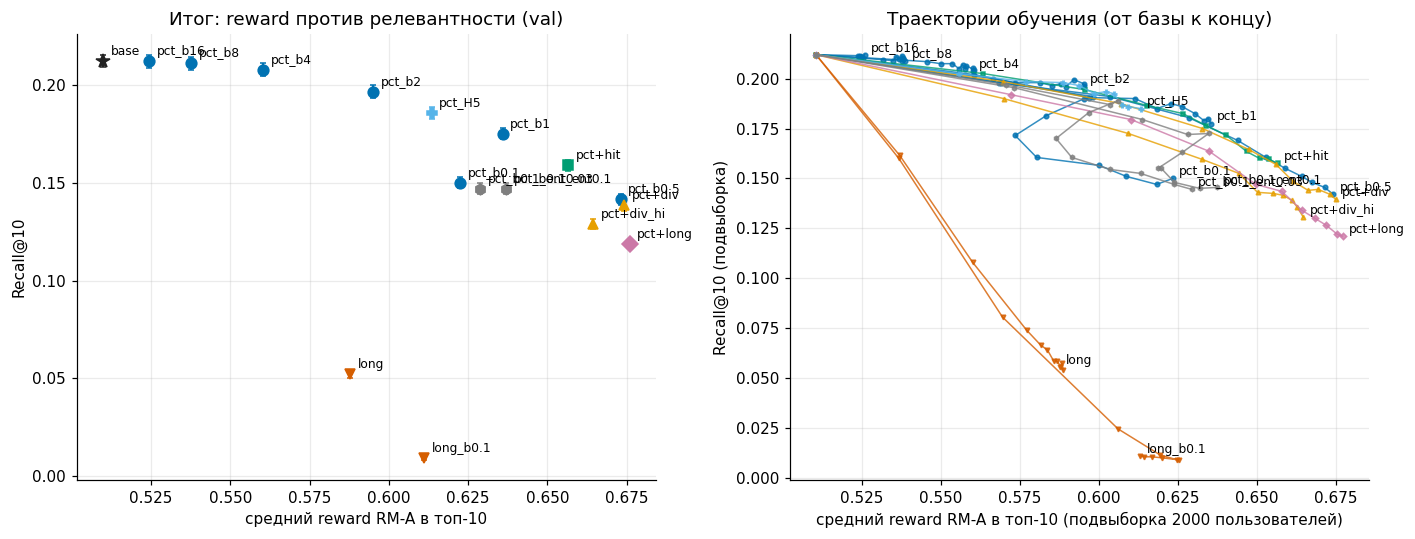

In [19]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "font.size": 10})
FAM = {"pct_b": ("#0072B2", "o"), "pct+hit": ("#009E73", "s"), "pct+div": ("#E69F00", "^"), "long": ("#D55E00", "v"),
       "pct+long": ("#CC79A7", "D"), "pct_H5": ("#56B4E9", "P")}
def fam(name):
    if "_ent" in name: return ("#7F7F7F", "h")
    for k in ("pct+long", "pct+hit", "pct+div", "pct_H5", "pct_b", "long"):
        if name.startswith(k): return FAM[k]
    return ("#444444", "o")

import re
runs = [n for n in rl_results if n != "base" and not re.search(r"_s\d+$", n)]   # повторы по seed разбираются в 5.10
ld = lambda kind, n, split="val": np.load(CACHE/f"{kind}_{n}_{split}_{RUN_TAG}.npy")
logs = {n: pd.read_csv(RESULTS/f"rl_log_{n}_{RUN_TAG}.csv") for n in runs if (RESULTS/f"rl_log_{n}_{RUN_TAG}.csv").exists()}

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n, r in rl_results.items():
    if n != "base" and n not in runs: continue
    x = r["reward@10"]["RM-A"][0]; y, lo, hi = r["rank_metrics"]["Recall@10"]; col, mk = ("#222222", "*") if n == "base" else fam(n)
    ax[0].errorbar(x, y, yerr=[[y - lo], [hi - y]], fmt=mk, color=col, ms=9 if n == "base" else 7, capsize=2)
    ax[0].annotate(n, (x, y), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax[0].set(xlabel="средний reward RM-A в топ-10", ylabel="Recall@10", title="Итог: reward против релевантности (val)")
for n, lg in logs.items():
    col, mk = fam(n); ax[1].plot(lg.val_rmA_top10, lg.val_recall10_sub, color=col, marker=mk, ms=3, lw=1, alpha=.8)
    ax[1].annotate(n, (lg.val_rmA_top10.iloc[-1], lg.val_recall10_sub.iloc[-1]), textcoords="offset points", xytext=(4, 2), fontsize=8)
ax[1].set(xlabel="средний reward RM-A в топ-10 (подвыборка 2000 пользователей)", ylabel="Recall@10 (подвыборка)", title="Траектории обучения (от базы к концу)")
plt.tight_layout(); plt.savefig(RESULTS/f"fig_pareto_{RUN_TAG}.png", dpi=130); plt.show()

### 5.2 Разности с базой (парный бутстреп по пользователям, 95% ДИ)

In [20]:
base_um, base_recs_v = user_metrics(ld("ranks", "base")), ld("recs", "base"); base_rw = reward_at_k(base_recs_v, "val")
delta = {}
for n in runs:
    um, rw = user_metrics(ld("ranks", n)), reward_at_k(ld("recs", n), "val")
    delta[n] = {"ΔRecall@10": boot_ci(um["Recall@10"] - base_um["Recall@10"]), "ΔNDCG@10": boot_ci(um["NDCG@10"] - base_um["NDCG@10"]),
                "ΔRM-A": boot_ci(rw["RM-A"] - base_rw["RM-A"]), "ΔRM-B": boot_ci(rw["RM-B"] - base_rw["RM-B"]),
                "ΔRM-ret": boot_ci(rw["RM-ret"] - base_rw["RM-ret"])}
json.dump(delta, open(RESULTS/f"rl_delta_{RUN_TAG}.json", "w"), indent=1)
fmt_d = lambda v: f"{v[0]:+.4f} [{v[1]:+.4f}, {v[2]:+.4f}]"
pd.DataFrame({n: {k: fmt_d(v) for k, v in d.items()} for n, d in delta.items()}).T

,ΔRecall@10,ΔNDCG@10,ΔRM-A,ΔRM-B,ΔRM-ret
pct_b0.1,"-0.0623 [-0.0652, -0.0595]","-0.0493 [-0.0510, -0.0473]","+0.1127 [+0.1120, +0.1133]","+0.1120 [+0.1114, +0.1127]","-0.0059 [-0.0061, -0.0057]"
pct_b0.5,"-0.0708 [-0.0739, -0.0677]","-0.0479 [-0.0497, -0.0460]","+0.1632 [+0.1625, +0.1639]","+0.1632 [+0.1625, +0.1639]","+0.0155 [+0.0154, +0.0157]"
pct_b1,"-0.0373 [-0.0399, -0.0348]","-0.0274 [-0.0288, -0.0260]","+0.1260 [+0.1254, +0.1266]","+0.1258 [+0.1252, +0.1264]","+0.0110 [+0.0109, +0.0111]"
pct_b2,"-0.0158 [-0.0177, -0.0139]","-0.0133 [-0.0144, -0.0122]","+0.0853 [+0.0848, +0.0857]","+0.0852 [+0.0847, +0.0857]","+0.0075 [+0.0074, +0.0075]"
pct_b4,"-0.0046 [-0.0061, -0.0032]","-0.0052 [-0.0059, -0.0045]","+0.0504 [+0.0500, +0.0507]","+0.0503 [+0.0500, +0.0507]","+0.0043 [+0.0042, +0.0043]"
pct_b8,"-0.0012 [-0.0023, -0.0002]","-0.0019 [-0.0025, -0.0015]","+0.0277 [+0.0275, +0.0280]","+0.0277 [+0.0274, +0.0280]","+0.0023 [+0.0023, +0.0024]"
pct_b16,"-0.0002 [-0.0010, +0.0006]","-0.0009 [-0.0013, -0.0006]","+0.0146 [+0.0144, +0.0147]","+0.0145 [+0.0143, +0.0147]","+0.0012 [+0.0012, +0.0013]"
pct+hit,"-0.0534 [-0.0564, -0.0508]","-0.0352 [-0.0369, -0.0335]","+0.1467 [+0.1461, +0.1473]","+0.1466 [+0.1460, +0.1472]","+0.0142 [+0.0141, +0.0144]"
pct+div,"-0.0739 [-0.0769, -0.0707]","-0.0486 [-0.0504, -0.0467]","+0.1643 [+0.1636, +0.1650]","+0.1644 [+0.1637, +0.1651]","+0.0186 [+0.0184, +0.0187]"
pct+div_hi,"-0.0833 [-0.0864, -0.0803]","-0.0517 [-0.0536, -0.0499]","+0.1545 [+0.1538, +0.1552]","+0.1544 [+0.1538, +0.1551]","+0.0268 [+0.0266, +0.0269]"


### 5.3 Поведение: популярность, длительность, сериалы, схлопывание политики

In [21]:
def last_stats(n):
    lg = logs.get(n); return {} if lg is None else lg.dropna(subset=["kl"]).iloc[-1][["kl", "entropy"]].to_dict()
beh = {n: {**r["behavior"], **last_stats(n)} for n, r in rl_results.items() if n == "base" or n in runs}
cols = ["mean_log_pop@10", "mean_dur_min", "share_series", "mean_item_pct_prior", "coverage@10", "gini@10", "overlap_with_base@10", "kl", "entropy"]
pd.DataFrame(beh).T.reindex(columns=cols).round(3)

,mean_log_pop@10,mean_dur_min,share_series,mean_item_pct_prior,coverage@10,gini@10,overlap_with_base@10,kl,entropy
base,8.999,390.697,0.299,51.009,0.243,0.981,NaN,NaN,NaN
pct_b0.1,10.206,212.570,0.226,62.747,0.015,0.999,0.388,4.456,0.056
pct_b0.5,9.600,155.975,0.091,68.334,0.082,0.997,0.388,1.275,3.285
pct_b1,9.263,167.770,0.118,64.455,0.177,0.991,0.584,0.344,4.906
pct_b2,9.111,205.520,0.171,60.077,0.222,0.985,0.744,0.093,5.502
pct_b4,9.060,252.110,0.223,56.341,0.233,0.983,0.852,0.026,5.710
pct_b8,9.031,303.242,0.256,53.929,0.237,0.982,0.916,0.007,5.792
pct_b16,9.013,342.942,0.276,52.537,0.239,0.982,0.951,0.002,5.835
pct+hit,9.471,160.478,0.103,66.638,0.122,0.995,0.475,0.829,3.716
pct+div,9.444,149.019,0.077,68.561,0.087,0.997,0.387,1.030,3.829


### 5.4 Кто теряет качество: длина истории и уровень вовлечённости

In [22]:
hl = np.array([len(h) for h in histories("val")])
ctx_v, clen_v, cp_v = contexts("val")
eng = ((cp_v * (ctx_v != 0)).sum(1) / clen_v.clamp(min=1)).numpy()                       # средний досмотр в истории
groups = {"история 5–9": hl < 10, "история 10–24": (hl >= 10) & (hl < 25), "история ≥25": hl >= 25}
q1, q2 = np.quantile(eng, [1 / 3, 2 / 3])
groups.update({"вовлечённость: низкая": eng <= q1, "вовлечённость: средняя": (eng > q1) & (eng <= q2), "вовлечённость: высокая": eng > q2})
sel = [n for n in ("pct_b0.5", "pct+hit", "pct+div", "long_b0.1", "pct_H5") if n in rl_results]
rk = {n: ld("ranks", n) for n in ["base"] + sel}
seg = {g: {"n": int(m.sum()), **{n: float((rk[n][m] <= 10).mean()) for n in rk}} for g, m in groups.items()}
seg = pd.DataFrame(seg).T
for n in sel: seg[f"Δ {n}"] = seg[n] - seg["base"]
seg.round(4)

,n,base,pct_b0.5,pct+hit,pct+div,long_b0.1,pct_H5,Δ pct_b0.5,Δ pct+hit,Δ pct+div,Δ long_b0.1,Δ pct_H5
история 5–9,22463.0,0.2504,0.1720,0.1926,0.1689,0.0074,0.2173,-0.0784,-0.0578,-0.0815,-0.2430,-0.0331
история 10–24,23514.0,0.2062,0.1359,0.1525,0.1322,0.0093,0.1811,-0.0703,-0.0536,-0.0740,-0.1969,-0.0250
история ≥25,12196.0,0.1540,0.0961,0.1089,0.0941,0.0121,0.1356,-0.0579,-0.0451,-0.0599,-0.1419,-0.0184
вовлечённость: низкая,19398.0,0.2208,0.1509,0.1671,0.1465,0.0063,0.1951,-0.0699,-0.0537,-0.0743,-0.2145,-0.0257
вовлечённость: средняя,19386.0,0.2165,0.1407,0.1590,0.1382,0.0076,0.1870,-0.0759,-0.0575,-0.0783,-0.2090,-0.0295
вовлечённость: высокая,19389.0,0.1996,0.1329,0.1505,0.1305,0.0135,0.1745,-0.0667,-0.0491,-0.0691,-0.1861,-0.0251


### 5.5 Какие объекты получают экспозицию

In [23]:
meta = pd.read_csv(DATA_DIR/"items.csv", usecols=["item_id", "title", "content_type"]).drop_duplicates("item_id").set_index("item_id")
expo = lambda recs: np.bincount(recs[:, :10].ravel(), minlength=n_items) / recs[:, :10].size
e0 = expo(base_recs_v)
print("доля слотов у топ-100 объектов: base =", round(float(np.sort(e0)[::-1][:100].sum()), 3))
for n in [x for x in ("pct_b0.5", "long_b0.1") if x in rl_results]:
    e1 = expo(ld("recs", n)); d = e1 - e0; top = np.argsort(-d)[:8]
    print(f"\n{n}: доля слотов у топ-100 объектов = {np.sort(e1)[::-1][:100].sum():.3f}; объекты с наибольшим ростом экспозиции")
    display(pd.DataFrame({"название": meta.title.reindex(idx2id[top]).values, "тип": meta.content_type.reindex(idx2id[top]).values,
                          "доля слотов было": e0[top].round(4), "стало": e1[top].round(4), "длит., мин": item_dur[top].round(),
                          "ср. досмотр в train, %": item_mean[top].round(1), "просмотров в train": item_cnt[top]}))

доля слотов у топ-100 объектов: base = 0.728

pct_b0.5: доля слотов у топ-100 объектов = 0.967; объекты с наибольшим ростом экспозиции


,название,тип,доля слотов было,стало,"длит., мин","ср. досмотр в train, %",просмотров в train
0,Белый снег,film,0.0100,0.0721,135.0,70.6,22143
1,День города,film,0.0021,0.0636,98.0,71.5,16011
2,Аферистка,film,0.0011,0.0581,124.0,67.2,16695
3,Маша,film,0.0120,0.0568,94.0,67.6,29731
4,Стендап под прикрытием,film,0.0042,0.0426,115.0,68.2,12568
5,Прабабушка легкого поведения,film,0.0484,0.0753,100.0,78.8,41520
6,Девятаев,film,0.0424,0.0656,116.0,73.6,64655
7,Пара из будущего,film,0.0011,0.0216,109.0,75.2,4555



long_b0.1: доля слотов у топ-100 объектов = 1.000; объекты с наибольшим ростом экспозиции


,название,тип,доля слотов было,стало,"длит., мин","ср. досмотр в train, %",просмотров в train
0,Железный человек 2,film,0.0004,0.0988,124.0,72.2,1884
1,Первый мститель: Другая война,film,0.0007,0.0987,135.0,67.9,1907
2,Тор,film,0.0007,0.0985,112.0,66.3,2498
3,Первый мститель,film,0.0007,0.0984,121.0,70.5,2402
4,Железный человек 3,film,0.0007,0.0983,127.0,68.2,2105
5,Железный человек,film,0.0009,0.0979,123.0,68.8,2637
6,Мстители: Эра Альтрона,film,0.0012,0.0982,140.0,67.8,2826
7,Стражи Галактики,film,0.0022,0.0973,120.0,69.2,4194


### 5.6 Проверка без reward model: что реально случилось с этими объектами в val

Для рекомендованных объектов считаем **фактический** средний `watched_pct` и долю возвратов за 3 дня по событиям val (минимум 20 событий на объект). Эти числа RM не использовали, поэтому они показывают, не эксплуатирует ли политика ошибки RM. Оговорка: это средние по объекту, а не персональные исходы; объекты без поддержки в таблицу не попадают (доля с поддержкой указана).

In [24]:
v_ = df[df.period == 1]
ia = v_.groupby("item").watched_pct.agg(["size", "mean"]); ir = v_[v_.ret_valid].groupby("item").ret.agg(["size", "mean"])
obs_pct = np.full(n_items, np.nan); obs_pct[ia.index[ia["size"] >= 20]] = ia["mean"][ia["size"] >= 20]
obs_ret = np.full(n_items, np.nan); obs_ret[ir.index[ir["size"] >= 20]] = ir["mean"][ir["size"] >= 20]
def obs(recs):
    r = recs[:, :10]
    return {"факт. досмотр, %": float(np.nanmean(obs_pct[r])), "факт. возврат 3д": float(np.nanmean(obs_ret[r])),
            "доля слотов с поддержкой": float(np.isfinite(obs_pct[r]).mean())}
obs_tab = pd.DataFrame({n: obs(ld("recs", n)) for n in ["base"] + runs}).T
obs_tab["ΔRM-A к базе"] = [0.0] + [delta[n]["ΔRM-A"][0] for n in runs]
obs_tab.to_csv(RESULTS/f"rl_observed_{RUN_TAG}.csv"); obs_tab.round(4)

,"факт. досмотр, %",факт. возврат 3д,доля слотов с поддержкой,ΔRM-A к базе
base,46.7120,0.5181,0.9651,0.0000
pct_b0.1,54.9141,0.5007,0.9999,0.1127
pct_b0.5,59.5140,0.5393,0.9959,0.1632
pct_b1,57.1079,0.5362,0.9831,0.1260
pct_b2,53.7807,0.5305,0.9727,0.0853
pct_b4,50.8820,0.5252,0.9690,0.0504
pct_b8,49.0074,0.5219,0.9673,0.0277
pct_b16,47.9225,0.5203,0.9661,0.0146
pct+hit,58.5728,0.5395,0.9916,0.1467
pct+div,59.7680,0.5462,0.9948,0.1643


### 5.7 Релевантность по следующим 6 событиям

Recall@10 по одному следующему объекту может недооценивать модель, если пользователь посмотрит рекомендованное чуть позже. Здесь релевантное множество – цель и до 5 следующих событий периода. **Recall-set@10** – доля этого множества в топ-10, **HitAny@10** – доля пользователей, у которых в топ-10 есть хотя бы одно такое событие.

In [25]:
S_val = np.full((len(evals["val"]), 1 + N_FUTURE), -1, np.int64)
for i, (t_, f_) in enumerate(zip(evals["val"].target.values, evals["val"].future.values)):
    S_val[i, 0] = t_; S_val[i, 1:1 + len(f_)] = f_
def set_metrics(recs, S=S_val, k=10):
    hit = (recs[:, :k, None] == S[:, None, :]).any(1)
    return {"Recall-set@10": hit.sum(1) / (S >= 0).sum(1), "HitAny@10": (hit.sum(1) > 0).astype(float)}
sm = {n: set_metrics(ld("recs", n)) for n in ["base"] + runs}
r1 = {n: (ld("ranks", n) <= 10).mean() for n in ["base"] + runs}
set_tab = pd.DataFrame({n: {"Recall@10 (1 событие)": r1[n], "Recall-set@10": boot_ci(m["Recall-set@10"])[0], "HitAny@10": m["HitAny@10"].mean()}
                        for n, m in sm.items()}).T
set_tab["отн. к базе, 1 событие"] = set_tab["Recall@10 (1 событие)"] / set_tab.loc["base", "Recall@10 (1 событие)"]
set_tab["отн. к базе, 6 событий"] = set_tab["Recall-set@10"] / set_tab.loc["base", "Recall-set@10"]
set_tab.to_csv(RESULTS/f"rl_set_relevance_{RUN_TAG}.csv"); set_tab.round(4)

,Recall@10 (1 событие),Recall-set@10,HitAny@10,"отн. к базе, 1 событие","отн. к базе, 6 событий"
base,0.2123,0.2012,0.3494,1.0000,1.0000
pct_b0.1,0.1500,0.1418,0.2556,0.7063,0.7051
pct_b0.5,0.1415,0.1324,0.2491,0.6664,0.6581
pct_b1,0.1750,0.1645,0.2998,0.8243,0.8179
pct_b2,0.1965,0.1858,0.3288,0.9256,0.9236
pct_b4,0.2077,0.1963,0.3435,0.9781,0.9757
pct_b8,0.2111,0.1995,0.3480,0.9944,0.9918
pct_b16,0.2121,0.2008,0.3493,0.9989,0.9983
pct+hit,0.1589,0.1493,0.2753,0.7483,0.7420
pct+div,0.1384,0.1296,0.2442,0.6519,0.6443


### 5.8 «Знакомый контент»: жанровое сходство с историей

Повторов (пользователь, объект) в KION нет, а просмотренное мы исключаем, поэтому знакомость измеряем косвенно, по жанрам: косинус жанрового вектора объекта с жанровым профилем истории пользователя, доля объектов хотя бы с одним жанром из истории и доля объектов, все жанры которых уже встречались. Ориентир – реальный следующий объект пользователя.

In [26]:
from collections import Counter
from scipy import sparse
genres = (pd.read_csv(DATA_DIR/"items.csv", usecols=["item_id", "genres"]).drop_duplicates("item_id").set_index("item_id")
          .genres.reindex(idx2id[1:]).fillna("").str.split(r",\s*"))
g_cnt = Counter(g for ts in genres for g in ts if g)
g_id = {g: j for j, g in enumerate(g for g, c_ in g_cnt.items() if c_ >= 50)}
G = np.zeros((n_items, len(g_id)), np.float32)
for i_, ts in enumerate(genres, start=1):
    for g in ts:
        if g in g_id: G[i_, g_id[g]] = 1
hist_v = histories("val")
U = sparse.csr_matrix((np.ones(sum(map(len, hist_v)), np.float32),
                       (np.repeat(np.arange(len(hist_v)), [len(h) for h in hist_v]), np.concatenate(hist_v).astype(np.int64))),
                      shape=(len(hist_v), n_items))
prof = np.asarray(U @ G); prof_n = prof / np.maximum(np.linalg.norm(prof, axis=1, keepdims=True), 1e-9); known = prof > 0

def familiarity(items, chunk=5000):
    s_cos = s_any = s_all = 0.0; n_ = 0
    for i in range(0, len(items), chunk):
        Gi = G[items[i:i + chunk]]; norm = np.linalg.norm(Gi, axis=-1); has = norm > 0
        inter = (Gi * known[i:i + chunk, None, :]).sum(-1)
        cos = (Gi * prof_n[i:i + chunk, None, :]).sum(-1) / np.maximum(norm, 1e-9)
        s_cos += cos[has].sum(); s_any += (inter[has] > 0).sum(); s_all += (inter[has] >= Gi.sum(-1)[has]).sum(); n_ += has.sum()
    return {"косинус жанров с историей": s_cos / n_, "есть жанр из истории": s_any / n_, "все жанры из истории": s_all / n_}

fam_tab = {"реальный следующий объект": familiarity(evals["val"].target.values[:, None])}
fam_tab.update({n: familiarity(ld("recs", n)[:, :10]) for n in ["base"] + runs})
fam_tab = pd.DataFrame(fam_tab).T
fam_tab.to_csv(RESULTS/f"rl_familiarity_{RUN_TAG}.csv"); print("жанров:", len(g_id)); fam_tab.round(3)

жанров: 49


,косинус жанров с историей,есть жанр из истории,все жанры из истории
реальный следующий объект,0.478,0.962,0.700
base,0.506,0.969,0.765
pct_b0.1,0.411,0.961,0.685
pct_b0.5,0.470,0.965,0.709
pct_b1,0.496,0.973,0.724
pct_b2,0.503,0.972,0.744
pct_b4,0.504,0.971,0.754
pct_b8,0.505,0.970,0.760
pct_b16,0.506,0.970,0.762
pct+hit,0.485,0.969,0.712


### 5.9 Какая часть прироста reward подтверждается фактическими исходами

Сравниваем прирост среднего RM-A в топ-10 (в п.п. доли просмотра) с приростом фактического досмотра тех же объектов в val (раздел 5.6). Если политика эксплуатирует ошибки RM, подтверждённая доля падает, а разрыв «RM − факт» растёт. Оговорка: факт – среднее по объекту, а RM-A завышена на несколько п.п. уже у базы из-за сдвига во времени.

In [27]:
base_obs = obs_tab.loc["base", "факт. досмотр, %"]
gain = pd.DataFrame({"ΔRM-A, п.п.": {n: delta[n]["ΔRM-A"][0] * 100 for n in runs},
                     "Δ факт. досмотр, п.п.": {n: obs_tab.loc[n, "факт. досмотр, %"] - base_obs for n in runs}})
gain["подтверждено, %"] = 100 * gain["Δ факт. досмотр, п.п."] / gain["ΔRM-A, п.п."]
gap = {n: rl_results[n]["reward@10"]["RM-A"][0] * 100 - obs_tab.loc[n, "факт. досмотр, %"] for n in ["base"] + runs}
gain = gain.reindex(["base"] + runs); gain["RM-A минус факт, п.п."] = pd.Series(gap)
gain.to_csv(RESULTS/f"rl_gain_confirmed_{RUN_TAG}.csv"); gain.round(2)

,"ΔRM-A, п.п.","Δ факт. досмотр, п.п.","подтверждено, %","RM-A минус факт, п.п."
base,NaN,NaN,NaN,4.28
pct_b0.1,11.27,8.20,72.79,7.34
pct_b0.5,16.32,12.80,78.44,7.80
pct_b1,12.60,10.40,82.52,6.48
pct_b2,8.53,7.07,82.92,5.73
pct_b4,5.04,4.17,82.74,5.15
pct_b8,2.77,2.30,82.72,4.76
pct_b16,1.46,1.21,83.17,4.52
pct+hit,14.67,11.86,80.84,7.09
pct+div,16.43,13.06,79.45,7.65


### 5.10 Разброс между запусками (seed 0, 1, 2)

In [28]:
seed_rows = {}
for n in [x for x in ("pct_b2", "pct_b8", "pct+hit") if x in rl_results]:
    names = [n] + [f"{n}_s{k}" for k in (1, 2) if f"{n}_s{k}" in rl_results]
    r10 = np.array([rl_results[x]["rank_metrics"]["Recall@10"][0] for x in names])
    rw = np.array([rl_results[x]["reward@10"]["RM-A"][0] for x in names])
    ci = rl_results[n]["rank_metrics"]["Recall@10"]
    seed_rows[n] = {"запусков": len(names), "Recall@10 среднее": r10.mean(), "Recall@10 sd": r10.std(ddof=1) if len(names) > 1 else np.nan,
                    "Recall@10 min": r10.min(), "Recall@10 max": r10.max(), "ширина ДИ по пользователям (seed 0)": ci[2] - ci[1],
                    "RM-A среднее": rw.mean(), "RM-A sd": rw.std(ddof=1) if len(names) > 1 else np.nan}
seed_tab = pd.DataFrame(seed_rows).T
seed_tab.to_csv(RESULTS/f"rl_seeds_{RUN_TAG}.csv"); seed_tab.round(4)

,запусков,Recall@10 среднее,Recall@10 sd,Recall@10 min,Recall@10 max,ширина ДИ по пользователям (seed 0),RM-A среднее,RM-A sd
pct_b2,3.0,0.1964,0.0010,0.1954,0.1973,0.0065,0.5955,0.0009
pct_b8,3.0,0.2109,0.0003,0.2106,0.2111,0.0066,0.5375,0.0007
pct+hit,3.0,0.1578,0.0009,0.1572,0.1589,0.0057,0.6577,0.0010


### Выводы по разделу 5

- Чем сильнее оптимизация, тем короче рекомендации. Оценка длительности топ-10: 391 мин у базы, 303 (β=8), 252 (β=4), 206 (β=2), 156 мин (β=0.5). Доля сериалов 0.30 → 0.26 / 0.22 / 0.17 / 0.09, средний досмотр рекомендованных объектов в train 51% → 54 / 56 / 60 / 68%. Объяснение: RM в основном учит эффект объекта (среднее по объекту уже даёт AUC 0.672), поэтому политика находит объекты с высокой долей досмотра, а это короткие фильмы.
- Персонализация теряется. При β=0.5 перекрытие рекомендаций с базой 0.39, покрытие 0.243 → 0.082, 97% слотов приходится на 100 объектов (у базы 73%). Потеря Recall@10 одинакова по группам: относительно базы −31% / −34% / −38% для истории 5–9 / 10–24 / ≥25 и −32% / −35% / −33% для низкой / средней / высокой вовлечённости. Политика ведёт себя как почти неперсонализированный «топ коротких хитов».
- Объекты с наибольшим ростом экспозиции: при β=0.5 фильмы на 94–135 мин с досмотром 67–72% и десятками тысяч просмотров (Белый снег, День города, Аферистка, Маша); у `long_b0.1` фильмы серии Marvel.
- Потеря релевантности не артефакт метрики по одному объекту (5.7): по множеству из 6 следующих событий относительная потеря почти та же (β=0.5: 0.658 от базы против 0.666 по одному событию; β=2: 0.924 против 0.926).
- RL не уходит в «знакомый контент» (5.8). Наоборот, база рекомендует жанры из истории чаще, чем пользователи их реально смотрят: косинус жанров с историей 0.506 против 0.478 у реального следующего объекта, «все жанры уже встречались» 0.765 против 0.700. Слабый RL (β ≥ 2) этого не меняет (0.503–0.506), сильный сдвигает к реальности (β=0.5: 0.471 и 0.709), схлопнувшиеся политики уходят от истории (β=0.1: 0.411; `long_b0.1`: 0.358 и 0.522). Reward выжимается через короткие фильмы, а не через повторение знакомого.
- Рост reward в основном реален (5.9): фактический досмотр подтверждает около 83% прироста RM-A при β ≥ 1, 78% при β=0.5 и 73% при β=0.1. Разрыв «RM-A минус факт» растёт с 4.3 п.п. у базы до 7.8 п.п. при β=0.5: чем сильнее давление оптимизации, тем больше RM завышает выбранные объекты. У `long` факт превышает прирост RM-A (102–121%): эта политика оптимизирует другую RM, а фильмы Marvel хорошо досматривают.

## 6. Генерация на 5 шагов вперёд

**Постановка.** Для пользователей val, у которых есть минимум 5 реальных событий в периоде (цель + 4 следующих), строим последовательность из 5 шагов: на каждом шаге берём топ-1, добавляем его в контекст, рекомендуем дальше. Два режима:

- **free** – в контекст добавляется собственная рекомендация (то, что произойдёт на практике при цепочке рекомендаций);
- **teacher** – в контекст добавляется реальное событие пользователя (контроль: что было бы, если бы пользователь следовал реальной траектории).

Метрики по шагам t = 1…5: Recall@10 относительно реального t-го события, reward RM-A и RM-B топ-1 (у добавленных объектов отклик «неизвестен»), доля уникальных объектов среди пользователей на шаге t (схлопывание), доля реальных событий, попавших в сгенерированную цепочку (sequence recall). Разность free − teacher показывает цену того, что сгенерированные объекты не являются настоящими взаимодействиями. Уже предложенные и добавленные в контекст объекты маскируются: в free-режиме объект, угаданный раньше, на следующем шаге недоступен, а в teacher-режиме недоступны уже прошедшие реальные события. Поэтому sequence recall сравниваем только между моделями внутри режима, а не между режимами.

In [29]:
H_MS, N_MS = 5, 20000
lpop_t = torch.log1p(torch.tensor(item_cnt, dtype=torch.float32, device=DEVICE))

@torch.no_grad()
def multistep(model, H=H_MS, n_max=N_MS, bs=512):
    e = evals["val"]; elig = np.array([len(f) + 1 >= H for f in e.future.values])
    idx = np.sort(np.random.default_rng(0).permutation(np.flatnonzero(elig))[:n_max])
    ctx_all, clen_all, cp_all = contexts("val")
    real = torch.tensor(np.stack([[e.target.values[i], *e.future.values[i][:H - 1]] for i in idx]), dtype=torch.long)
    res = {"n_users": int(len(idx))}
    for mode in ("free", "teacher"):
        per = {k: [[] for _ in range(H)] for k in ("hit", "rmA", "rmB", "lpop")}; gen = []
        for i in range(0, len(idx), bs):
            sl = idx[i:i + bs]
            c, l, q = ctx_all[sl].to(DEVICE), clen_all[sl].to(DEVICE), cp_all[sl].to(DEVICE); rb = real[i:i + bs].to(DEVICE); g = []
            for t in range(H):
                top = masked_logits(model, c, l).topk(10, 1).indices; a = top[:, 0]
                per["hit"][t].append((top == rb[:, t:t + 1]).any(1).float().cpu())
                per["rmA"][t].append(rm_candidates(rm, c, l, a[:, None], q)[:, 0].cpu())
                per["rmB"][t].append(rm_candidates(rm_b, c, l, a[:, None], q)[:, 0].cpu())
                per["lpop"][t].append(lpop_t[a].cpu()); g.append(a)
                c, q, l = append_tok(c, l, q, a if mode == "free" else rb[:, t])
            gen.append(torch.stack(g, 1).cpu())
        gen = torch.cat(gen).numpy(); cat = lambda L: torch.cat(L).numpy()
        res[mode] = {k: [cat(per[k][t]) for t in range(H)] for k in per}
        res[mode]["seq_recall"] = np.array([len(set(g) & set(r)) / H for g, r in zip(gen, real.numpy())])
        res[mode]["uniq_share"] = [len(np.unique(gen[:, t])) / len(gen) for t in range(H)]
    return res

ms_names = ["base"] + [n for n in ("pct_b0.5", "pct+hit", "long_b0.1", "pct_H5") if n in rl_results]
def load_policy(n):
    if n == "base": return base
    m = new_model(); m.load_state_dict(torch.load(CKPT/f"rl_{n}_{RUN_TAG}.pt", map_location=DEVICE)); return m.eval()
ms = {}
for n in ms_names:
    ms[n] = multistep(load_policy(n))
print("пользователей в многошаговой оценке:", ms["base"]["n_users"])

ms_rows = []
for n, r in ms.items():
    for mode in ("free", "teacher"):
        for t in range(H_MS):
            ms_rows.append(dict(model=n, mode=mode, step=t + 1, recall10=boot_ci(r[mode]["hit"][t]), rmA=boot_ci(r[mode]["rmA"][t]),
                                rmB=float(r[mode]["rmB"][t].mean()), uniq_share=r[mode]["uniq_share"][t], mean_log_pop=float(r[mode]["lpop"][t].mean()),
                                seq_recall=float(r[mode]["seq_recall"].mean())))
json.dump(ms_rows, open(RESULTS/f"multistep_{RUN_TAG}.json", "w"), indent=1)
ms_df = pd.DataFrame(ms_rows)
ms_df["Recall@10"] = ms_df.recall10.map(lambda v: f"{v[0]:.4f} [{v[1]:.4f}, {v[2]:.4f}]")
ms_df["RM-A топ-1"] = ms_df.rmA.map(lambda v: f"{v[0]:.3f}")
ms_df[ms_df["mode"] == "free"].pivot(index="model", columns="step", values="Recall@10")

пользователей в многошаговой оценке: 10761


step,1,2,3,4,5
model,,,,,
base,"0.1515 [0.1444, 0.1583]","0.1134 [0.1071, 0.1193]","0.0902 [0.0850, 0.0957]","0.0769 [0.0719, 0.0821]","0.0723 [0.0672, 0.0777]"
long_b0.1,"0.0142 [0.0120, 0.0165]","0.0139 [0.0119, 0.0161]","0.0138 [0.0116, 0.0162]","0.0125 [0.0106, 0.0145]","0.0138 [0.0116, 0.0162]"
pct+hit,"0.1223 [0.1164, 0.1287]","0.0891 [0.0838, 0.0945]","0.0750 [0.0703, 0.0799]","0.0641 [0.0596, 0.0689]","0.0525 [0.0483, 0.0566]"
pct_H5,"0.1392 [0.1329, 0.1461]","0.1018 [0.0960, 0.1068]","0.0839 [0.0792, 0.0890]","0.0728 [0.0676, 0.0776]","0.0668 [0.0621, 0.0715]"
pct_b0.5,"0.1136 [0.1079, 0.1196]","0.0793 [0.0742, 0.0844]","0.0637 [0.0593, 0.0683]","0.0523 [0.0483, 0.0569]","0.0435 [0.0400, 0.0475]"


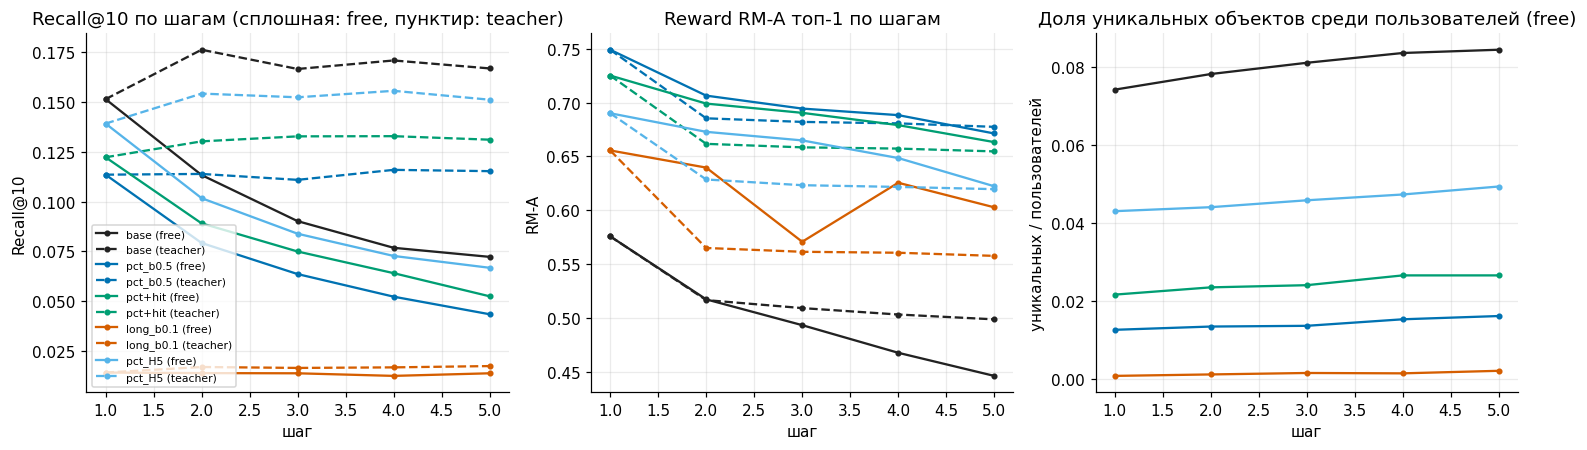

,seq_recall free,seq_recall teacher
base,0.0799,0.0540
pct_b0.5,0.0566,0.0217
pct+hit,0.0624,0.0327
long_b0.1,0.0062,0.0015
pct_H5,0.0700,0.0423


In [30]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
cols_ms = dict(zip(ms_names, ["#222222", "#0072B2", "#009E73", "#D55E00", "#56B4E9"]))
for n in ms_names:
    for mode, ls in (("free", "-"), ("teacher", "--")):
        d = ms_df[(ms_df.model == n) & (ms_df["mode"] == mode)]
        ax[0].plot(d.step, d.recall10.map(lambda v: v[0]), ls, color=cols_ms[n], marker="o", ms=3, label=f"{n} ({mode})")
        ax[1].plot(d.step, d.rmA.map(lambda v: v[0]), ls, color=cols_ms[n], marker="o", ms=3)
        if mode == "free": ax[2].plot(d.step, d.uniq_share, ls, color=cols_ms[n], marker="o", ms=3)
ax[0].set(title="Recall@10 по шагам (сплошная: free, пунктир: teacher)", xlabel="шаг", ylabel="Recall@10")
ax[1].set(title="Reward RM-A топ-1 по шагам", xlabel="шаг", ylabel="RM-A")
ax[2].set(title="Доля уникальных объектов среди пользователей (free)", xlabel="шаг", ylabel="уникальных / пользователей")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(RESULTS/f"fig_multistep_{RUN_TAG}.png", dpi=130); plt.show()
pd.DataFrame({n: {"seq_recall free": ms[n]["free"]["seq_recall"].mean(), "seq_recall teacher": ms[n]["teacher"]["seq_recall"].mean()} for n in ms}).T.round(4)

### Выводы по разделу 6

Оценка на 10 761 пользователе с ≥5 событиями в периоде.

- Цепочка из собственных рекомендаций быстро расходится с реальностью. Базовая модель: Recall@10 на шаге 1 равен 0.152, на шаге 5 в режиме free 0.072, в режиме teacher 0.167. К 5-му шагу релевантность free вдвое ниже, при реальном продолжении она не падает. RL-модели ведут себя так же: pct_b0.5 0.114 → 0.044 (free) против 0.115 (teacher).
- Reward RM-A у free-цепочки базовой модели падает с 0.576 до 0.447 (у teacher до 0.499). Из этих чисел нельзя отделить два объяснения: модель выбирает менее «досматриваемые» объекты или RM смещена на непривычном контексте. У RL-моделей reward остаётся высоким в обоих режимах (pct_b0.5: 0.749 → 0.671 free, 0.677 teacher): они выбирают объекты с высоким приором, контекст на них влияет слабо.
- Схлопывание видно по доле уникальных топ-1 среди пользователей: 0.074 у базы, 0.013 у pct_b0.5, 0.001 у long_b0.1 (около 9 разных объектов на 10 761 пользователей).
- Обучение с горизонтом 5 (pct_H5) сохраняет на 5-м шаге больше релевантности, чем одношаговая модель с тем же β (free 0.067 против 0.044), но достигает меньшего reward. Из-за разницы в силе оптимизации эффект горизонта от неё отделить нельзя.
- Следствие для оценки: на сгенерированных последовательностях reward нельзя считать настоящим откликом. RM не видела таких контекстов (отклик «неизвестен»), а метрики против реальных событий занижаются по построению.

## 7. Варианты функции вознаграждения и компромисс

**7.1** Компромисс: для каждого прогона прирост reward (по RM-A) против изменения Recall@10 с ДИ. Порог «заметной потери» – снижение Recall@10 больше чем на 0.005 (≈2.4% от базового значения).

**7.2** Финальная оценка на **test** (открывается один раз): базовая модель, бейзлайны и все RL-прогоны, одна и та же функция оценки и один и тот же протокол. Ничего не подбиралось по test.

,ΔRM-A,ΔRecall@10,ΔNDCG@10,потеря заметна,прирост reward на 0.01 потери Recall
pct+long,0.1661,-0.0936,-0.0613,да,0.0177
pct+div,0.1643,-0.0739,-0.0486,да,0.0222
pct_b0.5,0.1632,-0.0708,-0.0479,да,0.0230
pct+div_hi,0.1545,-0.0833,-0.0517,да,0.0185
pct+hit,0.1467,-0.0534,-0.0352,да,0.0275
pct_b0.1_ent0.1,0.1270,-0.0655,-0.0507,да,0.0194
pct_b1,0.1260,-0.0373,-0.0274,да,0.0338
pct_b0.1_ent0.03,0.1189,-0.0655,-0.0505,да,0.0182
pct_b0.1,0.1127,-0.0623,-0.0493,да,0.0181
pct_H5,0.1036,-0.0267,-0.0198,да,0.0387


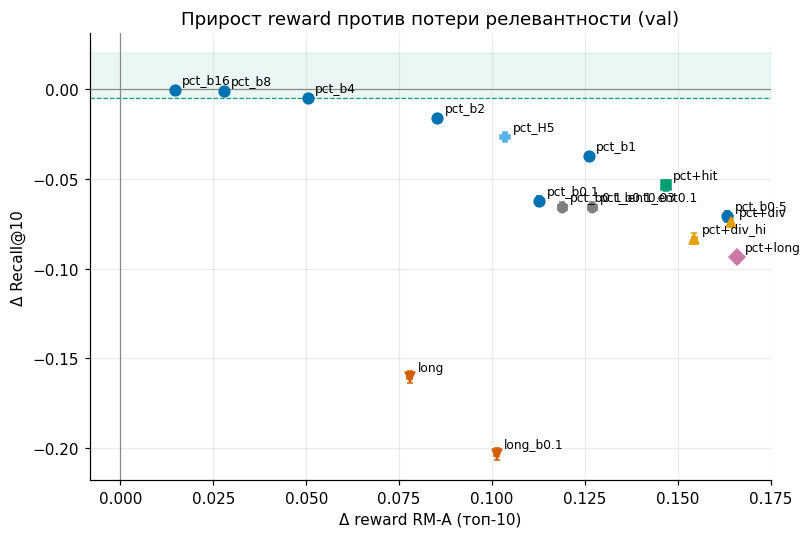

In [31]:
THR = 0.005
tr_ = pd.DataFrame({n: {"ΔRM-A": d["ΔRM-A"][0], "ΔRecall@10": d["ΔRecall@10"][0], "ΔNDCG@10": d["ΔNDCG@10"][0]} for n, d in delta.items()}).T
tr_["потеря заметна"] = np.where(tr_["ΔRecall@10"] < -THR, "да", "нет")
tr_["прирост reward на 0.01 потери Recall"] = np.where(tr_["ΔRecall@10"] < 0, tr_["ΔRM-A"] / (-tr_["ΔRecall@10"] * 100), np.nan)
display(tr_.sort_values("ΔRM-A", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.axhspan(-THR, 0.02, color="#009E73", alpha=.08)           # зона допустимой потери релевантности
for n, d in delta.items():
    (x, xl, xh), (y, yl, yh) = d["ΔRM-A"], d["ΔRecall@10"]; col, mk = fam(n)
    ax.errorbar(x, y, xerr=[[x - xl], [xh - x]], yerr=[[y - yl], [yh - y]], fmt=mk, color=col, capsize=2, ms=7)
    ax.annotate(n, (x, y), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.axhline(0, color="#888", lw=.8); ax.axvline(0, color="#888", lw=.8); ax.axhline(-THR, color="#009E73", lw=.8, ls="--")
ax.set(xlabel="Δ reward RM-A (топ-10)", ylabel="Δ Recall@10", title="Прирост reward против потери релевантности (val)")
plt.tight_layout(); plt.savefig(RESULTS/f"fig_tradeoff_{RUN_TAG}.png", dpi=130); plt.show()

### 7.2 Финальная оценка на test

In [32]:
ranks_b, recs_b = evaluate(gpt_scores(base), "test")
test_res = {"base": eval_recs("base", ranks_b, recs_b, "test")}; BASE_RECS_TEST = recs_b
pop_all_t = torch.tensor(item_cnt, dtype=torch.float32, device=DEVICE)
pop_7d_t = torch.tensor(np.bincount(df[df.period == 1].item.values, minlength=n_items) + 1e-6 * item_cnt, dtype=torch.float32, device=DEVICE)  # последняя неделя до test
for nm, vec in (("Pop (all time)", pop_all_t), ("Pop (last 7d)", pop_7d_t)):
    r_, rec_ = evaluate(lambda c, l, v=vec: v[None].expand(len(c), -1), "test")
    test_res[nm] = eval_recs(nm.replace(" ", "_"), r_, rec_, "test", BASE_RECS_TEST)
for n in runs:
    pol = load_policy(n); test_res[n], _ = full_eval(n, pol, "test", base_recs=BASE_RECS_TEST); del pol
    if DEVICE == "cuda": torch.cuda.empty_cache()
json.dump(test_res, open(RESULTS/f"test_{RUN_TAG}.json", "w"), indent=1)
rl_table(test_res)

,Recall@10,NDCG@10,rwd RM-A,rwd RM-B,rwd ret,overlap w/ base,coverage,gini,"dur, мин",сериалы
base,0.1961,0.1163,0.506,0.506,0.562,1.00,0.260,0.980,390,0.30
Pop (all time),0.1388,0.0835,0.509,0.510,0.550,0.35,0.002,0.999,276,0.47
Pop (last 7d),0.1837,0.0989,0.454,0.454,0.536,0.35,0.002,0.999,443,0.42
pct_b0.1,0.1453,0.0752,0.620,0.619,0.556,0.38,0.015,0.999,211,0.22
pct_b0.5,0.1331,0.0754,0.671,0.671,0.578,0.38,0.086,0.997,154,0.09
pct_b1,0.1593,0.0925,0.633,0.633,0.573,0.58,0.195,0.990,166,0.11
pct_b2,0.1795,0.1042,0.591,0.591,0.570,0.74,0.238,0.984,204,0.17
pct_b4,0.1900,0.1110,0.556,0.556,0.566,0.85,0.250,0.982,252,0.22
pct_b8,0.1936,0.1139,0.534,0.534,0.565,0.91,0.255,0.981,304,0.25
pct_b16,0.1948,0.1151,0.520,0.520,0.563,0.95,0.258,0.981,343,0.27


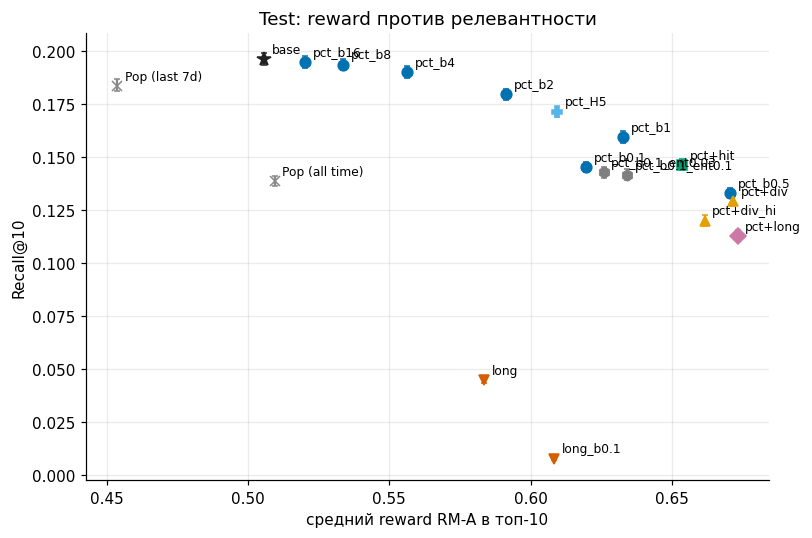

In [33]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for n, r in test_res.items():
    x = r["reward@10"]["RM-A"][0]; y, lo, hi = r["rank_metrics"]["Recall@10"]
    col, mk = ("#222222", "*") if n == "base" else (("#888888", "x") if n.startswith("Pop") else fam(n))
    ax.errorbar(x, y, yerr=[[y - lo], [hi - y]], fmt=mk, color=col, capsize=2, ms=9 if n == "base" else 7)
    ax.annotate(n, (x, y), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set(xlabel="средний reward RM-A в топ-10", ylabel="Recall@10", title="Test: reward против релевантности")
plt.tight_layout(); plt.savefig(RESULTS/f"fig_test_{RUN_TAG}.png", dpi=130); plt.show()

### 7.3 Reward model на test

Те же модели и бейзлайны, что в разделе 3, но на событиях test. Пользовательское среднее считается по train+val (всё, что было до test).

In [34]:
p_t, y_t, u_t, it_t = rm_predict(rm, "test")
tv_ = df[df.period <= 1].groupby("user_id").watched_pct.agg(["sum", "count"])
user_mean_t = ((tv_["sum"] + K_SH * g_mean) / (tv_["count"] + K_SH)).reindex(evals["test"].index[u_t]).fillna(g_mean).values
preds_t = {"Константа": np.full_like(y_t, g_mean), "Среднее по объекту": item_mean[it_t], "Среднее по пользователю": user_mean_t,
           "Объект + пользователь": np.clip(item_mean[it_t] + user_mean_t - g_mean, 0, 100),
           "RM (отклики контекста неизвестны)": rm_predict(rm, "test", use_pct=False)[0], "RM (отклики известны)": p_t}
rm_test = boot_reg(preds_t, y_t, u_t, len(evals["test"]))
json.dump(rm_test, open(RESULTS/f"rm_test_{TAG}.json", "w"), indent=1)
print("событий test:", len(y_t), "| доля watched>=50:", round(float((y_t >= 50).mean()), 3))
pd.DataFrame({m: {**{k: fmt(r, k) for k in ("MAE", "RMSE", "AUC")}, "Spearman": f"{r['Spearman']:.4f}"} for m, r in rm_test.items()}).T

/tmp/ipykernel_24/733233993.py:19: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  Spearman=float(spearmanr(p, y)[0])) for m, p in preds.items()}


событий test: 281458 | доля watched>=50: 0.417


,MAE,RMSE,AUC,Spearman
Константа,"37.4166 [37.3418, 37.4986]","40.1930 [40.1378, 40.2560]","0.5000 [0.5000, 0.5000]",nan
Среднее по объекту,"33.6931 [33.6078, 33.7714]","38.3251 [38.2525, 38.4066]","0.6593 [0.6572, 0.6617]",0.3325
Среднее по пользователю,"34.7500 [34.6401, 34.8521]","38.8802 [38.7812, 38.9643]","0.6429 [0.6396, 0.6464]",0.2738
Объект + пользователь,"31.5485 [31.4256, 31.6524]","37.5538 [37.4311, 37.6505]","0.7092 [0.7062, 0.7120]",0.4238
RM (отклики контекста неизвестны),"33.0592 [32.9486, 33.1663]","37.9861 [37.8756, 38.0827]","0.6671 [0.6646, 0.6702]",0.3459
RM (отклики известны),"30.3825 [30.2647, 30.4809]","35.6316 [35.5297, 35.7217]","0.7369 [0.7341, 0.7394]",0.4690


### Выводы по разделу 7

- Без заметной потери (порог 0.005 по Recall@10) reward можно поднять до β=4: Recall@10 −0.0046 [−0.0061, −0.0032] (−2.2% от базы), RM-A +0.050 (0.510 → 0.560), фактический досмотр 46.7% → 50.9%. При β=8: −0.0012, +0.028, факт 49.0%; при β=16 потеря статистически неотличима от нуля (−0.0002 [−0.0010, +0.0006]), RM-A +0.015. Уже при β=2 потеря −0.016 (−7%).
- Прирост RM-A на 0.01 потери Recall@10 быстро падает с ростом давления оптимизации: 0.73 (β=16), 0.23 (β=8), 0.11 (β=4), 0.054 (β=2), 0.034 (β=1), 0.023 (β=0.5).
- Среди вариантов наград при β=0.5: горизонт 5 – 0.039, бонус `hit` – 0.028, чистая доля просмотра – 0.023, штраф за скопление – 0.022, смесь с долгосрочной – 0.018, `long` – 0.005.
- Test подтверждает порядок. Recall@10: база 0.196 [0.194, 0.199], популярное за 7 дней 0.184, β=16 0.195, β=8 0.194, β=4 0.190, β=2 0.180, β=1 0.159, β=0.5 0.133, pct_H5 0.172. На test потеря у β=4 чуть больше, чем на val (−0.006, −3%), граница допустимого проходит между β=4 и β=8. Ни один RL-вариант не превосходит базу по Recall и NDCG. Ничего на test не подбиралось.
- Reward model на test (7.3) держит качество: AUC 0.737 против 0.745 на val, выигрыш над средним по объекту сохраняется (ΔRMSE −2.7 [−2.8, −2.6]).

## 8. Выводы и ограничения

**Ответы на вопросы задания.**

1. *Удаётся ли максимизировать reward?* Да: RM-A в топ-10 0.510 → 0.560 (β=4) … 0.673 (β=0.5); фактический досмотр рекомендованных объектов в val 46.7% → 50.9% … 59.5%, около 80% прироста по RM подтверждается фактом. Рекомендации смещаются к коротким фильмам с высокой долей досмотра (391 → 156 мин), покрытие падает с 0.243 до 0.082, перекрытие с базой 0.39.
2. *Сохраняется ли релевантность?* Только при сильном KL. Recall@10 0.212 → 0.211 (β=8), 0.208 (β=4), 0.197 (β=2), 0.142 (β=0.5); при слабом KL политика схлопывается (энтропия 0.06, 220 объектов на каталог), бонус за энтропию этого не исправляет. Потеря одинакова по группам пользователей и по 6 следующим событиям: персонализация исчезает. Ухода в «знакомый» контент нет.
3. *Долгосрочные цели.* Награда «вернулся в течение 3 дней» предсказывается слабо за счёт объекта (AUC 0.684 против 0.649 у пользовательского среднего), и оптимизация по ней приводит к эксплуатации: Recall@10 0.052 / 0.009, при β=0.1 рекомендуются одни и те же около 10 фильмов. Офлайн проверяются релевантность, поведение и фактические исходы по логам; причинный эффект на возврат и удовлетворённость требует онлайн-эксперимента.
4. *Генерация на несколько шагов.* Цепочка из собственных рекомендаций теряет релевантность вдвое к 5-му шагу (Recall@10 0.152 → 0.072; при реальном продолжении 0.167), reward сгенерированного контекста RM оценивает вне своего распределения.
5. *Компромисс.* До β=4 reward растёт почти без потери точности (+0.050 при −0.005 Recall@10), дальше обмен резко ухудшается. Рычаги – β и функция награды: бонус `hit` возвращает часть релевантности, штраф за скопление, бонус за энтропию и долгосрочная награда не помогают.

**Ограничения.**

- Повторы по seed есть только для трёх конфигураций (разброс мал), остальные – по одному запуску.
- Релевантность считается по реальным событиям (одно следующее или 6 следующих): для рекомендованных, но не просмотренных объектов исход неизвестен.
- В KION только дата без времени, нет лайков и длительности объектов (длительность оценена косвенно по `total_dur` и доле досмотра).
- RM-B почти копия RM-A (корреляция 0.985), независимой награды нет. Фактический досмотр в разделе 5.6 – среднее по объекту, не персональный исход.
- Повторных просмотров в данных нет, повторные рекомендации напрямую не исследованы (знакомость оценена по жанрам).
- Многошаговая оценка сделана на пользователях с ≥5 событиями в периоде (выборка смещена к активным).
- Всё офлайн: влияние на реальное поведение и возврат не измерялось.

**Направления дальнейшей работы.** Адаптивный β с целевым KL вместо фиксированного; ограниченная оптимизация (максимум reward при Recall ≥ база − ε, множитель Лагранжа); явное ограничение энтропии против схлопывания; причинная оценка долгосрочной награды (онлайн A/B или офлайн-оценка по пропенсити); обучение RM на контекстах из сгенерированных объектов.